**Introducción a la Ciencia de Datos 2026**  
Posgrado en Ciencias de la Computación — CICESE  
**Profesor:** Dr. Irvin Hussein López Nava  
**Estudiante:** Luis Felipe García Domínguez  

# Identificación de Especies de Aves por Audio (BirdCLEF 2026)

Este proyecto evalúa la clasificación automática de especies de aves a partir de grabaciones de campo, comparando descriptores acústicos clásicos (**MFCCs + deltas**) frente a representaciones profundas preentrenadas en bioacústica (**Perch**) bajo condiciones reales de ruido ambiental, variación entre grabadores y presencia simultánea de varias especies.

### Contexto y procedencia del conjunto de datos

- **Fuente oficial:** Competencia **[BirdCLEF 2026](https://www.kaggle.com/competitions/birdclef-2026)** en Kaggle (organizada por el *Cornell Lab of Ornithology* y *LifeCLEF*), construida a partir de grabaciones colaborativas de **Xeno-canto** e **iNaturalist**.
- **¿Qué mide y qué contiene?** El conjunto original reúne **35,549 grabaciones** en formato `.ogg` (32 kHz, canal mono) descritas en `train.csv` (15 columnas) y clasificadas taxonómicamente en `taxonomy.csv` (**234 especies** de aves, anfibios, insectos y mamíferos). Cada registro incluye la especie principal (`primary_label`), especies secundarias audibles de fondo (`secondary_labels`), calificación de calidad (`rating`, escala 0–5), autor y ubicación geográfica.
- **Subconjunto final de estudio:** Tras filtrar a la clase *Aves* y auditar empíricamente duración, sesgo por autor y espectro acústico, el experimento se concentra en **30 especies balanceadas** (15 de vocalizaciones graves y 15 de vocalizaciones agudas), sumando **4,793 grabaciones** (2,235 limpias y 2,558 de estrés) y **15,834 ventanas activas** de 5 segundos.

### Preguntas de investigación

1. **P1:** ¿Resultan más fáciles de identificar las aves con cantos graves que las de cantos agudos usando métodos clásicos? *Criterio:* diferencia significativa en F1 por especie (prueba U de Mann-Whitney, $\alpha = 0.05$).
2. **P2:** ¿Permiten las representaciones profundas preentrenadas distinguir mejor las especies que suelen confundirse entre sí? *Criterio:* reducción de al menos 15 % en la tasa de error ($1 - \text{F1}$) en las tres especies más difíciles del mejor modelo clásico.
3. **P3:** ¿Qué enfoque resiste mejor el deterioro del audio cuando aumenta el ruido ambiental y cantan varias especies al mismo tiempo? *Criterio:* menor caída relativa de Macro-F1 al bajar la calidad del audio.

### Estructura del trabajo

- **Parte 1 — Exploración de datos tabulares (Secciones 1–8):** Auditoría de `train.csv` y `taxonomy.csv`, filtrado a *Aves*, definición de estratos de calidad, control de sesgo por autor y selección de 56 especies candidatas.
- **Parte 2 — Exploración acústica y selección de 30 especies (Secciones 9–12):** Medición empírica de duración, frecuencia dominante y centroide espectral sobre 1,120 audios `.ogg` para seleccionar 15 especies graves y 15 agudas bajo criterios estrictos de calidad.
- **Parte 3 — Preprocesamiento y extracción de características (Secciones 13–17):** Segmentación en ventanas de 5 s (50 % de traslape), filtro de actividad vocal en 350–8,500 Hz con planicidad espectral (Top-$k$, $k=4$), carga de 80 MFCCs + deltas y *embeddings* de Perch (1,280 dimensiones, `float16 -> float32`), junto con proyecciones exploratorias PCA y UMAP.
- **Parte 4 — Modelado supervisado y validación sin fugas (Secciones 18–19):** Partición `StratifiedGroupKFold` (5 pliegues agrupados por `filename`), optimización de hiperparámetros con `GridSearchCV` para `SVM (MFCC)`, `Random Forest (MFCC)` y `Perch (Embeddings)` e importancia de atributos.
- **Parte 5 — Evaluación, análisis de errores y cierre (Secciones 20–27):** Respuestas cuantitativas a P1, P2 y P3, evaluación agregada por grabación completa (`filename`), análisis cualitativo de errores con espectrogramas en estrés, trazabilidad de iteraciones, limitaciones, conclusiones generales y declaración de uso de IA.

---
# Parte 1: Exploración de Datos Tabulares

## 1. Configuración del entorno y carga de datos

Importamos las librerías necesarias para el análisis y visualización.

In [1]:
import sys
import importlib.metadata as md
import numpy as np

# Semilla para reproducibilidad
SEMILLA = 42
np.random.seed(SEMILLA)

# Versiones de Python y librerías principales del proyecto
paquetes = [
    'numpy', 'pandas', 'scipy', 'matplotlib', 'seaborn',
    'scikit-learn', 'librosa', 'umap-learn', 'tensorflow', 'kagglehub'
]
print(f"{'python':<14}: {sys.version.split()[0]}")
for pkg in paquetes:
    try:
        print(f"{pkg:<14}: {md.version(pkg)}")
    except md.PackageNotFoundError:
        print(f"{pkg:<14}: no instalado")

python        : 3.13.12
numpy         : 2.5.3
pandas        : 3.0.6
scipy         : 1.18.1
matplotlib    : 3.11.2
seaborn       : 0.13.2
scikit-learn  : 1.9.1
librosa       : 1.0.1
umap-learn    : 0.6.0
tensorflow    : 2.21.0
kagglehub     : 1.0.3


Configuramos algunas opciones para los gráficos. Especificamos las rutas a los datos tabulares y los cargamos.

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de gráficos
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 13
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

# Rutas de los archivos de datos tabulares
RUTA_DATOS = '../data'
RUTA_TRAIN = os.path.join(RUTA_DATOS, 'train.csv')
RUTA_TAXONOMY = os.path.join(RUTA_DATOS, 'taxonomy.csv')

# Carga de datos
df_train = pd.read_csv(RUTA_TRAIN)
df_tax = pd.read_csv(RUTA_TAXONOMY)

print(f"Dimensiones de train.csv: {df_train.shape[0]:,} filas y {df_train.shape[1]} columnas.")
print(f"Dimensiones de taxonomy.csv: {df_tax.shape[0]} filas y {df_tax.shape[1]} columnas.")

Dimensiones de train.csv: 35,549 filas y 15 columnas.
Dimensiones de taxonomy.csv: 234 filas y 5 columnas.


**Lectura.**
`train.csv` contiene 35,549 registros y 15 columnas, mientras que `taxonomy.csv` registra 234 especies. Dado el tamaño del conjunto original y las diferencias en la calidad de las grabaciones, es necesario revisar los datos antes de seleccionar las especies de estudio.

## 2. Revisión de datos iniciales

### 2.1 Variables y valores faltantes
Revisamos las columnas, tipos de datos y la presencia de valores nulos.

In [3]:
# Resumen de columnas, tipos y valores nulos
resumen_nulos = pd.DataFrame({
    'Tipo de Dato': df_train.dtypes,
    'Valores Nulos': df_train.isnull().sum(),
    'Porcentaje Nulos (%)': (df_train.isnull().sum() / len(df_train)) * 100
})
resumen_nulos

,Tipo de Dato,Valores Nulos,Porcentaje Nulos (%)
primary_label,str,0,0.0
secondary_labels,str,0,0.0
type,str,0,0.0
latitude,float64,0,0.0
longitude,float64,0,0.0
scientific_name,str,0,0.0
common_name,str,0,0.0
class_name,str,0,0.0
inat_taxon_id,int64,0,0.0
author,str,0,0.0


**Lectura.**
No hay valores nulos en las columnas de `train.csv`. Cada registro incluye coordenadas (`latitude`, `longitude`), calificación de calidad (`rating`), autor (`author`) y el nombre del archivo de audio (`filename`). En estas tablas no existe ninguna columna con la duración del audio ni con su rango de frecuencias, por lo que esas propiedades se medirán directamente sobre los archivos `.ogg` en la Parte 2.

### 2.2 Origen de los datos y licencias
Revisamos de qué colecciones provienen los audios y bajo qué licencias se distribuyen.

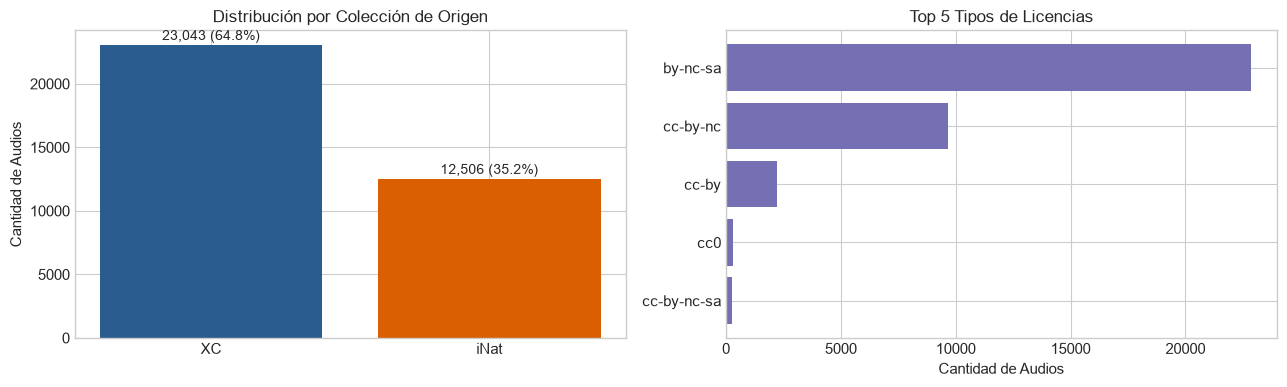

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

conteo_coleccion = df_train['collection'].value_counts()
axes[0].bar(conteo_coleccion.index, conteo_coleccion.values, color=['#2b5c8f', '#d95f02'])
axes[0].set_title('Distribución por Colección de Origen')
axes[0].set_ylabel('Cantidad de Audios')
for i, v in enumerate(conteo_coleccion.values):
    axes[0].text(i, v + 400, f"{v:,} ({v/len(df_train)*100:.1f}%)", ha='center', fontsize=10)

conteo_licencia = df_train['license'].value_counts().head(5)
axes[1].barh(conteo_licencia.index, conteo_licencia.values, color='#7570b3')
axes[1].set_title('Top 5 Tipos de Licencias')
axes[1].set_xlabel('Cantidad de Audios')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

**Lectura.**
El 64.8% de los audios proviene de *xeno-canto* y el 35.2% de *iNaturalist*. La mayoría cuenta con licencias Creative Commons (CC-BY-NC y CC-BY). Al ser grabaciones de ciencia ciudadana, existen diferencias en los tipos de micrófonos y condiciones de grabación.

### 2.3 Clases biológicas en el conjunto de datos
Revisamos la distribución de clases biológicas presentes en `taxonomy.csv` y en las grabaciones.

In [5]:
# Cuantificamos especies y grabaciones por clase biológica para justificar el filtrado a Aves
resumen_tax = df_tax['class_name'].value_counts().reset_index()
resumen_tax.columns = ['Clase Biológica', 'Especies Registradas']
resumen_tax['Porcentaje Especies (%)'] = (resumen_tax['Especies Registradas'] / len(df_tax)) * 100

resumen_audios = df_train['class_name'].value_counts().reset_index()
resumen_audios.columns = ['Clase Biológica', 'Audios Registrados']
resumen_audios['Porcentaje Audios (%)'] = (resumen_audios['Audios Registrados'] / len(df_train)) * 100

tabla_clases = pd.merge(resumen_tax, resumen_audios, on='Clase Biológica')
tabla_clases

,Clase Biológica,Especies Registradas,Porcentaje Especies (%),Audios Registrados,Porcentaje Audios (%)
0,Aves,162,69.230769,34799,97.890236
1,Amphibia,35,14.957265,451,1.268671
2,Insecta,28,11.965812,199,0.559791
3,Mammalia,8,3.418803,99,0.278489
4,Reptilia,1,0.427350,1,0.002813


**Lectura.**
De las 234 especies en el archivo de taxonomía, 162 son aves (69.2%). El resto corresponde a anfibios (35), insectos (28), mamíferos (8) y reptiles (1). Por ello, para este proyecto se filtran únicamente los registros correspondientes a la clase *Aves*.

## 3. Calidad de audio y presencia de cantos de fondo

La calidad de cada audio está calificada por los usuarios en una escala de 0.0 a 5.0 estrellas (`rating`). Además, la columna `secondary_labels` indica si se escuchan otras especies al mismo tiempo.

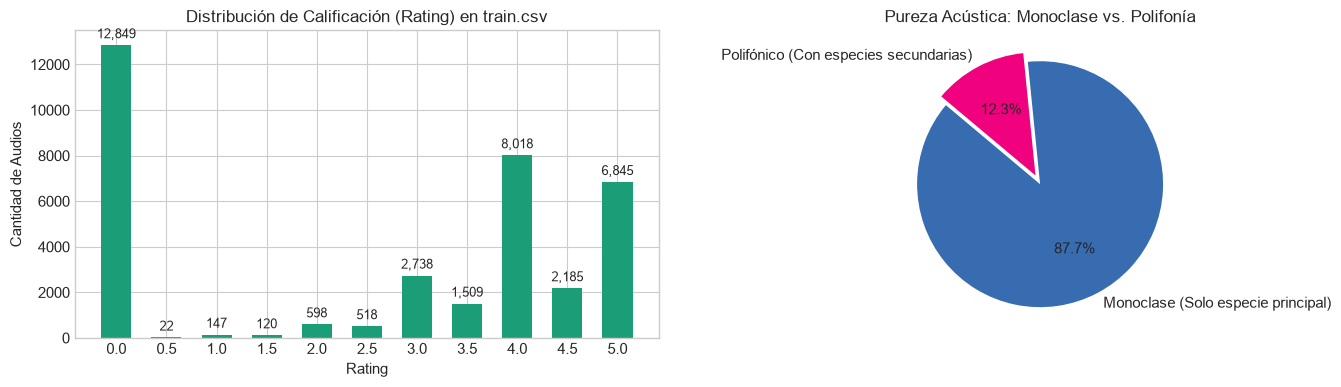

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

conteo_rating = df_train['rating'].value_counts().sort_index()
axes[0].bar(conteo_rating.index.astype(str), conteo_rating.values, color='#1b9e77', width=0.6)
axes[0].set_title('Distribución de Calificación (Rating) en train.csv')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Cantidad de Audios')
for i, (idx, val) in enumerate(conteo_rating.items()):
    axes[0].text(i, val + 300, f"{val:,}", ha='center', fontsize=9)

tiene_secundarias = (df_train['secondary_labels'] != '[]').value_counts()
etiquetas_sec = ['Monoclase (Solo especie principal)', 'Polifónico (Con especies secundarias)']
axes[1].pie(tiene_secundarias.values, labels=etiquetas_sec, autopct='%1.1f%%', 
            colors=['#386cb0', '#f0027f'], startangle=140, explode=(0, 0.08))
axes[1].set_title('Pureza Acústica: Monoclase vs. Polifonía')

plt.tight_layout()
plt.show()

**Lectura.**
La mayoría de las grabaciones tienen calificaciones entre 3.0 y 5.0. Sin embargo, el 12.3% de los audios incluye cantos de otras especies de fondo (`secondary_labels`), lo que refleja que en campo es común registrar más de un ave a la vez.

### 3.1 Definición de estratos de calidad
Para evaluar el efecto del ruido en la Pregunta 3, agrupamos las grabaciones en tres niveles:
1. **Alta Calidad:** `rating >= 4.0` y sin especies secundarias (`secondary_labels == '[]'`).
2. **Media Calidad:** `3.0 <= rating < 4.0` y sin especies secundarias.
3. **Estrés / Campo:** `rating < 3.0` o con presencia de especies secundarias.

In [7]:
def clasificar_estrato_bioacustico(row):
    """
    Clasifica una grabación en tres estratos según su calificación y pureza:
    - Alta Calidad (Referencia): rating >= 4.0 y secondary_labels == '[]'
    - Media Calidad (Campo Aceptable): 3.0 <= rating < 4.0 y secondary_labels == '[]'
    - Estrés / Campo Real: rating < 3.0 o secondary_labels != '[]'
    """
    rating = float(row['rating'])
    sin_secundarias = (row['secondary_labels'] == '[]')
    
    if rating >= 4.0 and sin_secundarias:
        return 'Alta Calidad (Referencia)'
    elif (3.0 <= rating < 4.0) and sin_secundarias:
        return 'Media Calidad (Campo Aceptable)'
    else:
        return 'Estrés / Campo Real'

df_train['estrato_calidad'] = df_train.apply(clasificar_estrato_bioacustico, axis=1)

resumen_estratos = df_train['estrato_calidad'].value_counts().reset_index()
resumen_estratos.columns = ['Estrato Bioacústico', 'Cantidad de Audios']
resumen_estratos['Porcentaje (%)'] = (resumen_estratos['Cantidad de Audios'] / len(df_train)) * 100
resumen_estratos

,Estrato Bioacústico,Cantidad de Audios,Porcentaje (%)
0,Estrés / Campo Real,17948,50.488059
1,Alta Calidad (Referencia),14863,41.809896
2,Media Calidad (Campo Aceptable),2738,7.702045


**Lectura.**
En el conjunto global, el 50.5% de los audios queda en el estrato de estrés, el 41.8% en alta calidad y el 7.7% en media calidad. Esto muestra que cerca de la mitad de las grabaciones de campo presentan ruido o cantos de otras especies.

## 4. Identificación de especies candidatas

### 4.1 Desbalance en los datos originales
Revisamos la cantidad de audios por especie en el conjunto original.

In [8]:
conteo_especies_raw = df_train['primary_label'].value_counts()

print(f"Especie con mayor cantidad de audios: '{conteo_especies_raw.index[0]}' con {conteo_especies_raw.max()} audios.")
print(f"Especie con menor cantidad de audios: '{conteo_especies_raw.index[-1]}' con {conteo_especies_raw.min()} audio.")
print(f"Razón de desbalance extremo: {conteo_especies_raw.max() / conteo_especies_raw.min():.0f}:1.")

Especie con mayor cantidad de audios: 'rubthr1' con 499 audios.
Especie con menor cantidad de audios: '516975' con 1 audio.
Razón de desbalance extremo: 499:1.


**Lectura.**
Existe una diferencia de 499 a 1 entre la especie con más audios (499) y la que tiene menos (1). Las especies con muy pocas grabaciones no permiten hacer validación cruzada de forma confiable, por lo que conviene acotar el estudio a especies con un número balanceado de muestras.

### 4.2 Filtro por ventana operativa ($50 \le N \le 100$ audios limpios)
Buscamos especies de la clase *Aves* que tengan entre 50 y 100 grabaciones limpias (`Alta` y `Media` calidad). Este rango garantiza al menos 10 muestras por pliegue en una validación cruzada de 5 particiones y mantiene un desbalance máximo de 2 a 1 entre clases.

In [9]:
# Filtro de audios limpios (Alta y Media calidad)
df_limpio_global = df_train[df_train['estrato_calidad'].isin(['Alta Calidad (Referencia)', 'Media Calidad (Campo Aceptable)'])].copy()

# Conteo de audios limpios por especie
conteo_limpio = df_limpio_global['primary_label'].value_counts()

# Especies en el rango operativo [50, 100]
especies_50_100 = conteo_limpio[(conteo_limpio >= 50) & (conteo_limpio <= 100)].index

# Cruzamos con taxonomy para confirmar que sean aves
aves_candidatas = df_tax[(df_tax['primary_label'].isin(especies_50_100)) & (df_tax['class_name'] == 'Aves')].copy()
aves_candidatas['audios_limpios'] = aves_candidatas['primary_label'].map(conteo_limpio)
aves_candidatas = aves_candidatas.sort_values(by='audios_limpios', ascending=False)

lista_candidatas = aves_candidatas['primary_label'].tolist()
print(f"Total de especies de aves candidatas (50 <= N <= 100): {len(lista_candidatas)}")
aves_candidatas[['primary_label', 'common_name', 'scientific_name', 'audios_limpios']].head(15)

Total de especies de aves candidatas (50 <= N <= 100): 56


,primary_label,common_name,scientific_name,audios_limpios
227,y00678,Crested Caracara,Caracara plancus,100
221,whbwar2,White-browed Warbler,Myiothlypis leucoblephara,98
94,bunibi1,Buff-necked Ibis,Theristicus caudatus,98
219,wfwduc1,White-faced Whistling Duck,Dendrocygna viduata,95
174,rufhor2,Rufous Hornero,Furnarius rufus,95
105,crbthr1,Creamy-bellied Thrush,Turdus amaurochalinus,94
201,spispi1,Spix's Spinetail,Synallaxis spixi,93
164,recfin1,Red-crested Finch,Coryphospingus cucullatus,93
99,chobla1,Chopi Blackbird,Gnorimopsar chopi,92
185,schpar1,Scaly-headed Parrot,Pionus maximiliani,91


**Lectura.**
Existen 56 especies de aves que cumplen con tener entre 50 y 100 grabaciones limpias. A partir de este grupo de 56 candidatas seleccionaremos el subconjunto definitivo en la Parte 2, una vez que inspeccionemos las frecuencias y duraciones reales de los audios para buscar un balance cercano al 50-50 entre especies graves y agudas.

## 5. Auditoría de estratos en las 56 especies candidatas

Extraemos todos los registros de `train.csv` correspondientes a las 56 especies candidatas (tanto audios limpios como de estrés) para verificar si todas disponen de suficientes grabaciones con ruido de campo para la Pregunta 3.

In [10]:
# Extracción de todos los audios para las 56 especies candidatas
df_candidatas_completo = df_train[df_train['primary_label'].isin(lista_candidatas)].copy()

print(f"Total de registros para las 56 especies candidatas: {len(df_candidatas_completo):,} filas.")
print("\nDistribución por estrato de calidad:")
print(df_candidatas_completo['estrato_calidad'].value_counts())

Total de registros para las 56 especies candidatas: 7,864 filas.

Distribución por estrato de calidad:
estrato_calidad
Estrés / Campo Real                3885
Alta Calidad (Referencia)          3336
Media Calidad (Campo Aceptable)     643
Name: count, dtype: int64


**Lectura.**
Las 56 especies candidatas suman 7,864 grabaciones en total: 3,979 limpias (3,336 de alta calidad y 643 de media calidad) y 3,885 en el estrato de estrés. Esto representa cerca del 22% del dataset original.

### 5.1 Matriz de contingencia: Especie vs. Estrato de Calidad
Revisamos cuántos audios tiene cada una de las 56 especies en los tres estratos y detectamos si alguna tiene muy pocos registros en condiciones de estrés.

In [11]:
# Auditamos cuántos audios limpios y de estrés tiene cada especie candidata para validar P3
orden_columnas = ['Alta Calidad (Referencia)', 'Media Calidad (Campo Aceptable)', 'Estrés / Campo Real']

matriz_cand_estrato = pd.crosstab(
    df_candidatas_completo['primary_label'],
    df_candidatas_completo['estrato_calidad']
)[orden_columnas]

matriz_cand_estrato['Limpios (Alta+Media)'] = (
    matriz_cand_estrato['Alta Calidad (Referencia)'] + 
    matriz_cand_estrato['Media Calidad (Campo Aceptable)']
)
matriz_cand_estrato['Total'] = matriz_cand_estrato.iloc[:, :3].sum(axis=1)

print(f"Mínimo de audios de estrés entre las 56 especies: {matriz_cand_estrato['Estrés / Campo Real'].min()}")
print(f"Mediana de audios de estrés: {matriz_cand_estrato['Estrés / Campo Real'].median():.0f}")
print("\nEspecies con menos de 15 audios en estrés:")
display(matriz_cand_estrato[matriz_cand_estrato['Estrés / Campo Real'] < 15])

print("\nResumen estadístico por estrato en las 56 especies:")
display(matriz_cand_estrato.describe().round(1))

Mínimo de audios de estrés entre las 56 especies: 11
Mediana de audios de estrés: 51

Especies con menos de 15 audios en estrés:


estrato_calidad,Alta Calidad (Referencia),Media Calidad (Campo Aceptable),Estrés / Campo Real,Limpios (Alta+Media),Total
primary_label,,,,,
ficman1,45,10,11,55,66



Resumen estadístico por estrato en las 56 especies:


estrato_calidad,Alta Calidad (Referencia),Media Calidad (Campo Aceptable),Estrés / Campo Real,Limpios (Alta+Media),Total
count,56.0,56.0,56.0,56.0,56.0
mean,59.6,11.5,69.4,71.1,140.4
std,15.3,5.3,50.5,15.9,59.4
min,24.0,2.0,11.0,50.0,66.0
25%,47.5,8.0,34.5,55.0,99.8
50%,61.5,10.5,51.0,69.5,123.5
75%,72.0,14.2,89.8,83.2,162.5
max,89.0,27.0,220.0,100.0,315.0


**Lectura.**
Todas las 56 especies tienen al menos 11 grabaciones en el estrato de estrés, y 55 de ellas cuentan con 15 o más (con una mediana de 51 audios de estrés por especie). Solo `ficman1` queda en el límite inferior con 11 audios de estrés.

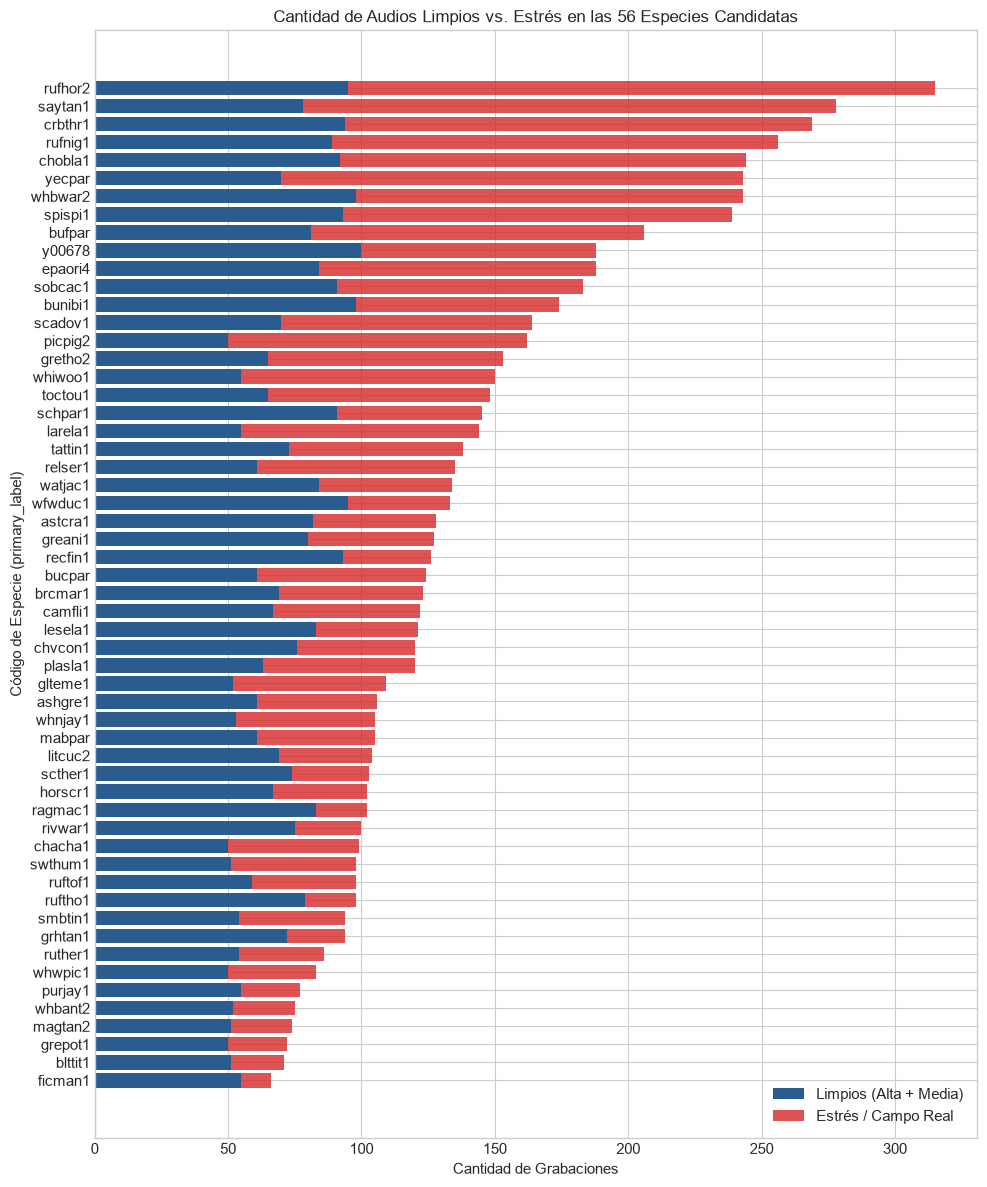

In [12]:
# Gráfico comparativo de audios limpios vs. estrés en las 56 especies candidatas
matriz_plot = matriz_cand_estrato.sort_values(by='Total', ascending=True)

fig, ax = plt.subplots(figsize=(10, 12))
ax.barh(matriz_plot.index, matriz_plot['Limpios (Alta+Media)'], label='Limpios (Alta + Media)', color='#2b5c8f')
ax.barh(matriz_plot.index, matriz_plot['Estrés / Campo Real'], 
        left=matriz_plot['Limpios (Alta+Media)'], label='Estrés / Campo Real', color='#d62728', alpha=0.8)

ax.set_title('Cantidad de Audios Limpios vs. Estrés en las 56 Especies Candidatas')
ax.set_xlabel('Cantidad de Grabaciones')
ax.set_ylabel('Código de Especie (primary_label)')
ax.legend()
plt.tight_layout()
plt.show()

**Lectura.**
Las 56 especies mantienen un rango acotado de audios limpios (entre 50 y 100), pero varían ampliamente en la cantidad de audios de estrés disponibles (desde 11 hasta más de 170). Esta información servirá como criterio adicional al elegir las especies definitivas en la Parte 2.

## 6. Revisión de autores y distribución geográfica

### 6.1 Variedad de autores por especie
Revisamos cuántos grabadores distintos aportaron audios en cada una de las 56 especies y si algún autor concentra un porcentaje alto de las grabaciones (lo cual podría generar sesgo por equipo de grabación).

In [13]:
# Medimos la concentración por grabador para detectar posibles sesgos de micrófono o localidad
resumen_autores = []
for sp in lista_candidatas:
    sub = df_candidatas_completo[df_candidatas_completo['primary_label'] == sp]
    n_audios = len(sub)
    n_autores = sub['author'].nunique()
    top_autor_pct = (sub['author'].value_counts().iloc[0] / n_audios) * 100
    common = sub['common_name'].iloc[0]
    resumen_autores.append({
        'primary_label': sp,
        'common_name': common,
        'audios_totales': n_audios,
        'autores_unicos': n_autores,
        'max_pct_top_autor': round(top_autor_pct, 1)
    })

df_autores = pd.DataFrame(resumen_autores)

print(f"Mínimo de autores únicos por especie: {df_autores['autores_unicos'].min()}")
print(f"Especies donde un solo autor supera el 30% de los audios:")
display(df_autores[df_autores['max_pct_top_autor'] > 30].sort_values(by='max_pct_top_autor', ascending=False))

Mínimo de autores únicos por especie: 24
Especies donde un solo autor supera el 30% de los audios:


,primary_label,common_name,audios_totales,autores_unicos,max_pct_top_autor
55,whwpic1,White-wedged Piculet,83,24,49.4
48,glteme1,Glittering-throated Emerald,109,35,44.0
39,ruftof1,Rusty-fronted Tody-Flycatcher,98,33,32.7
25,grhtan1,Grey-headed Tanager,94,35,30.9


**Lectura.**
Todas las especies candidatas tienen al menos 24 autores distintos. Sin embargo, en 4 especies (`whwpic1`, `glteme1`, `ruftof1` y `grhtan1`) un solo autor aporta entre el 30.9% y el 49.4% de los audios. Conviene tener en cuenta este dato al seleccionar el subconjunto final para evitar que un mismo grabador domine una clase.

### 6.2 Cobertura geográfica
Graficamos la ubicación de las grabaciones de las 56 especies candidatas según sus coordenadas.

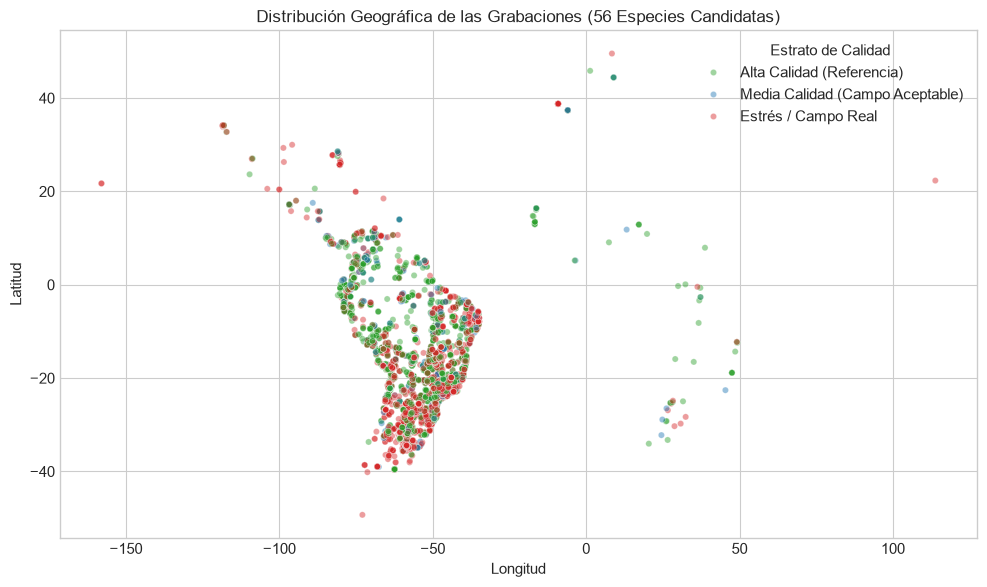

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=df_candidatas_completo,
    x='longitude',
    y='latitude',
    hue='estrato_calidad',
    palette={
        'Alta Calidad (Referencia)': '#2ca02c',
        'Media Calidad (Campo Aceptable)': '#1f77b4',
        'Estrés / Campo Real': '#d62728'
    },
    alpha=0.45,
    s=20,
    ax=ax
)

ax.set_title('Distribución Geográfica de las Grabaciones (56 Especies Candidatas)')
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.legend(title='Estrato de Calidad')
plt.tight_layout()
plt.show()

**Lectura.**
Las grabaciones se concentran principalmente en América del Sur y cubren un rango geográfico amplio. Los tres estratos de calidad se distribuyen de manera uniforme sobre la misma región.

## 7. Exportación de listas de candidatas para descarga de audio

Para evitar descargar los 35,549 archivos del dataset completo, guardamos en `project/data/`:
1. `candidatas_56_especies_completo.csv`: los 7,864 registros tabulares de las 56 especies candidatas con su columna `estrato_calidad`.
2. `muestra_descarga_56_especies.csv`: una muestra aleatoria estratificada de **20 audios limpios por especie** (1,120 archivos `.ogg` en total) para descargar primero desde Kaggle, medir duración y frecuencias reales, y elegir así el subconjunto definitivo.

In [15]:
# 1. Guardar tabla completa de las 56 candidatas
ruta_cand_completo = os.path.join(RUTA_DATOS, 'candidatas_56_especies_completo.csv')
df_candidatas_completo.to_csv(ruta_cand_completo, index=False)

# 2. Generar muestra de 20 audios limpios por especie (1,120 audios) para inspeccionar duración y tono
df_cand_limpio = df_candidatas_completo[
    df_candidatas_completo['estrato_calidad'].isin(['Alta Calidad (Referencia)', 'Media Calidad (Campo Aceptable)'])
].copy()

df_muestra = (
    df_cand_limpio.groupby('primary_label', group_keys=False)
    .sample(n=20, random_state=42)
    .reset_index(drop=True)
)

ruta_muestra = os.path.join(RUTA_DATOS, 'muestra_descarga_56_especies.csv')
df_muestra.to_csv(ruta_muestra, index=False)

print(f"Archivo completo de candidatas guardado: '{ruta_cand_completo}' ({len(df_candidatas_completo):,} filas).")
print(f"Archivo de muestra para descarga guardado: '{ruta_muestra}' ({len(df_muestra):,} filas).")

Archivo completo de candidatas guardado: '../data/candidatas_56_especies_completo.csv' (7,864 filas).
Archivo de muestra para descarga guardado: '../data/muestra_descarga_56_especies.csv' (1,120 filas).


**Lectura.**
Con `muestra_descarga_56_especies.csv` tenemos exactamente 1,120 rutas `filename` listas para descargar y analizar en la Parte 2 sin saturar el espacio en disco ni el tiempo de descarga.

## 8. Conclusiones de la Parte 1 (EDA Tabular) y Siguientes Pasos

A partir de la auditoría de `train.csv` y `taxonomy.csv`, el filtrado a la clase *Aves* descartó el 30.8% de las especies no aviares y permitió acotar el universo a **56 especies candidatas** que cuentan con entre 50 y 100 grabaciones limpias (`Alta` y `Media` calidad). En conjunto, estas especies reúnen 7,864 registros (3,979 limpios y 3,885 en condiciones de estrés), con una disponibilidad amplia de grabaciones ruidosas o polifónicas para poner a prueba la Pregunta 3. Al mismo tiempo, la revisión de autores identificó 4 especies donde un solo grabador concentra más del 30% del material (`whwpic1`, `glteme1`, `ruftof1` y `grhtan1`), un posible sesgo de micrófono o localidad que se controlará explícitamente antes de cerrar el subconjunto.

Dado que los metadatos tabulares no informan sobre la duración real ni sobre el rango frecuencial de los cantos, la Parte 2 pasa a inspeccionar directamente una muestra de grabaciones `.ogg` de las 56 candidatas. Con esas mediciones empíricas se descartarán especies con exceso de fragmentos menores a 5 segundos y se clasificará cada especie por su frecuencia dominante y centroide espectral reales, con el fin de conformar un subconjunto balanceado (mitad graves y mitad agudas) que sustente la Pregunta 1.

---
# Parte 2: Exploración de Audio y Selección del Subconjunto Final

Con la muestra descargada de **1,120 archivos `.ogg`** (20 grabaciones limpias por cada una de las 56 especies candidatas), analizamos las propiedades reales de las señales de audio para tomar la decisión final de qué especies formarán el conjunto de trabajo.

En esta parte revisamos:
1. **Propiedades técnicas y duración:** frecuencia de muestreo original, canales, duración mínima, mediana y máxima por especie, y porcentaje de grabaciones menores a 5 segundos.
2. **Grupo tonal real:** medición de la frecuencia dominante y del centroide espectral sobre los segmentos activos de cada audio (banda biológica de 300 a 10,500 Hz).
3. **Selección definitiva:** cruce de criterios tabulares y acústicos para definir un subconjunto equilibrado entre especies graves y agudas.

## 9. Medición de duración y frecuencias en la muestra de audio

Para evitar recalcular los 1,120 archivos cada vez que se ejecute el notebook, guardamos las métricas por archivo en `../data/metricas_muestra_56_especies.csv`. Si el archivo ya existe, lo cargamos directamente.

In [16]:
import soundfile as sf
import librosa

RUTA_MUESTRA = os.path.join(RUTA_DATOS, 'muestra_descarga_56_especies.csv')
RUTA_AUDIO = os.path.join(RUTA_DATOS, 'train_audio')
RUTA_METRICAS_MUESTRA = os.path.join(RUTA_DATOS, 'metricas_muestra_56_especies.csv')

if os.path.exists(RUTA_METRICAS_MUESTRA):
    df_metricas_audio = pd.read_csv(RUTA_METRICAS_MUESTRA)
    print(f"Métricas cargadas desde caché: {len(df_metricas_audio)} archivos.")
else:
    df_muestra = pd.read_csv(RUTA_MUESTRA)
    registros = []

    for _, row in df_muestra.iterrows():
        ruta_ogg = os.path.join(RUTA_AUDIO, row['filename'])
        info = sf.info(ruta_ogg)

        # Cargamos hasta 60 segundos a 22,050 Hz en mono para explorar la señal
        y, sr = librosa.load(ruta_ogg, sr=22050, mono=True, duration=60.0)
        S = np.abs(librosa.stft(y, n_fft=1024, hop_length=512))
        freqs = librosa.fft_frequencies(sr=sr, n_fft=1024)

        # Banda biológica (300 Hz a 10,500 Hz) para evitar ruido grave de viento
        mask_bio = (freqs >= 300) & (freqs <= 10500)
        S_bio = S[mask_bio, :]
        freqs_bio = freqs[mask_bio]

        # Nos quedamos con el 25% de frames más energéticos (actividad vocal)
        energia_frame = np.sum(S_bio**2, axis=0)
        umbral = np.percentile(energia_frame, 75)
        frames_activos = energia_frame >= umbral

        if np.any(frames_activos):
            S_act = S_bio[:, frames_activos]
            pesos = np.sum(S_act, axis=0) + 1e-10
            centroides = np.sum(freqs_bio[:, None] * S_act, axis=0) / pesos
            centroide_hz = float(np.median(centroides))
            pico_hz = float(np.median(freqs_bio[np.argmax(S_act, axis=0)]))
        else:
            centroide_hz = np.nan
            pico_hz = np.nan

        registros.append({
            'primary_label': row['primary_label'],
            'common_name': row['common_name'],
            'filename': row['filename'],
            'duracion_s': info.duration,
            'sr_original': info.samplerate,
            'canales': info.channels,
            'centroide_hz': centroide_hz,
            'pico_hz': pico_hz
        })

    df_metricas_audio = pd.DataFrame(registros)
    df_metricas_audio.to_csv(RUTA_METRICAS_MUESTRA, index=False)
    print(f"Métricas calculadas y guardadas: {len(df_metricas_audio)} archivos.")

print("Frecuencias de muestreo originales:", df_metricas_audio['sr_original'].value_counts().to_dict())
print("Canales originales:", df_metricas_audio['canales'].value_counts().to_dict())

Métricas cargadas desde caché: 1120 archivos.
Frecuencias de muestreo originales: {32000: 1120}
Canales originales: {1: 1120}


**Lectura.**
Todos los 1,120 archivos de la muestra vienen grabados a 32,000 Hz en un solo canal (mono). Esto confirma que el remuestreo posterior a 22,050 Hz en la Parte 3 se aplicará de forma uniforme sobre todas las pistas.

### 9.1 Revisión de piso y techo de duración por especie
Agrupamos las mediciones por especie para revisar las duraciones mínimas, medianas, máximas y el porcentaje de audios que miden menos de una ventana de 5 segundos.

In [17]:
# Agregamos duración y frecuencias dominantes por especie sobre la muestra de 1,120 audios
resumen_especies_audio = df_metricas_audio.groupby(['primary_label', 'common_name']).agg(
    n_muestra=('duracion_s', 'count'),
    dur_min=('duracion_s', 'min'),
    dur_mediana=('duracion_s', 'median'),
    dur_max=('duracion_s', 'max'),
    pct_menor_5s=('duracion_s', lambda x: (x < 5.0).mean() * 100),
    centroide_med=('centroide_hz', 'median'),
    pico_med=('pico_hz', 'median')
).reset_index()

print(f"Rango de duraciones medianas entre especies: {resumen_especies_audio['dur_mediana'].min():.1f} s a {resumen_especies_audio['dur_mediana'].max():.1f} s")
print(f"Duración mínima global: {resumen_especies_audio['dur_min'].min():.2f} s | Máxima global: {resumen_especies_audio['dur_max'].max():.1f} s")
print("\nEspecies con más de 15% de audios menores a 5 segundos:")
display(resumen_especies_audio[resumen_especies_audio['pct_menor_5s'] > 15].sort_values('pct_menor_5s', ascending=False))

Rango de duraciones medianas entre especies: 10.9 s a 40.5 s
Duración mínima global: 2.55 s | Máxima global: 351.6 s

Especies con más de 15% de audios menores a 5 segundos:


,primary_label,common_name,n_muestra,dur_min,dur_mediana,dur_max,pct_menor_5s,centroide_med,pico_med
54,y00678,Crested Caracara,20,2.760000,11.546125,126.093063,30.0,3324.744343,1733.422852
14,glteme1,Glittering-throated Emerald,20,4.231000,26.644906,223.399188,20.0,5834.067741,6266.162109
36,ruther1,Rufescent Tiger Heron,20,2.586125,17.496609,121.051000,20.0,3517.704151,1776.489258
41,smbtin1,Small-billed Tinamou,20,3.160813,12.106016,198.144000,20.0,2914.957745,2110.253906


**Lectura.**
Las medianas de duración se ubican entre 10.9 s y 40.5 s, un rango adecuado para extraer ventanas de 5 segundos. Sin embargo, 4 especies superan el 15% de grabaciones menores a 5 segundos: `y00678` (30%), `ruther1` (20%), `smbtin1` (20%) y `glteme1` (20%). Descartar especies con alta proporción de clips muy cortos evita depender de relleno artificial (*padding*) en las ventanas.

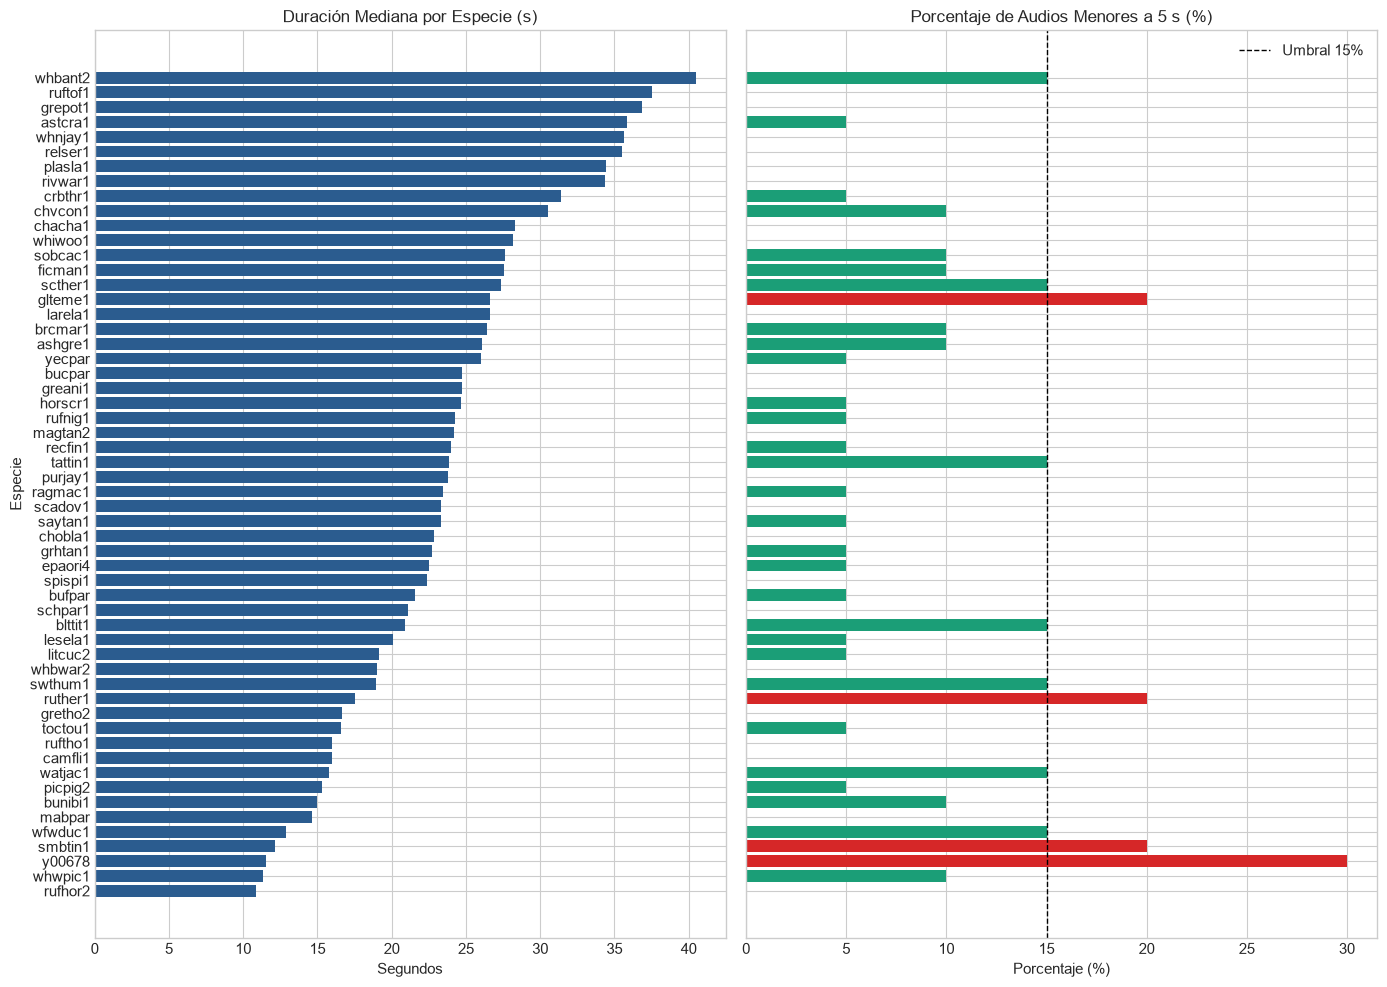

In [18]:
# Gráfica de duración mediana y proporción de audios < 5s por especie
fig, axes = plt.subplots(1, 2, figsize=(14, 10), sharey=True)

df_ord_dur = resumen_especies_audio.sort_values('dur_mediana', ascending=True)

axes[0].barh(df_ord_dur['primary_label'], df_ord_dur['dur_mediana'], color='#2b5c8f')
axes[0].set_title('Duración Mediana por Especie (s)')
axes[0].set_xlabel('Segundos')
axes[0].set_ylabel('Especie')

colores_5s = ['#d62728' if v > 15 else '#1b9e77' for v in df_ord_dur['pct_menor_5s']]
axes[1].barh(df_ord_dur['primary_label'], df_ord_dur['pct_menor_5s'], color=colores_5s)
axes[1].axvline(15, color='black', linestyle='--', linewidth=1, label='Umbral 15%')
axes[1].set_title('Porcentaje de Audios Menores a 5 s (%)')
axes[1].set_xlabel('Porcentaje (%)')
axes[1].legend()

plt.tight_layout()
plt.show()

**Lectura.**
En la mayoría de las 56 especies, entre el 0% y el 10% de los audios miden menos de 5 segundos. Las barras en rojo señalan las 4 especies que superan el límite del 15%.

## 10. Análisis del grupo tonal (frecuencia dominante y centroide espectral)

Ordenamos las 56 especies según su frecuencia dominante mediana (`pico_med`) para observar cómo se distribuyen en el espectro de frecuencias y comprobar qué especies son realmente graves y cuáles agudas.

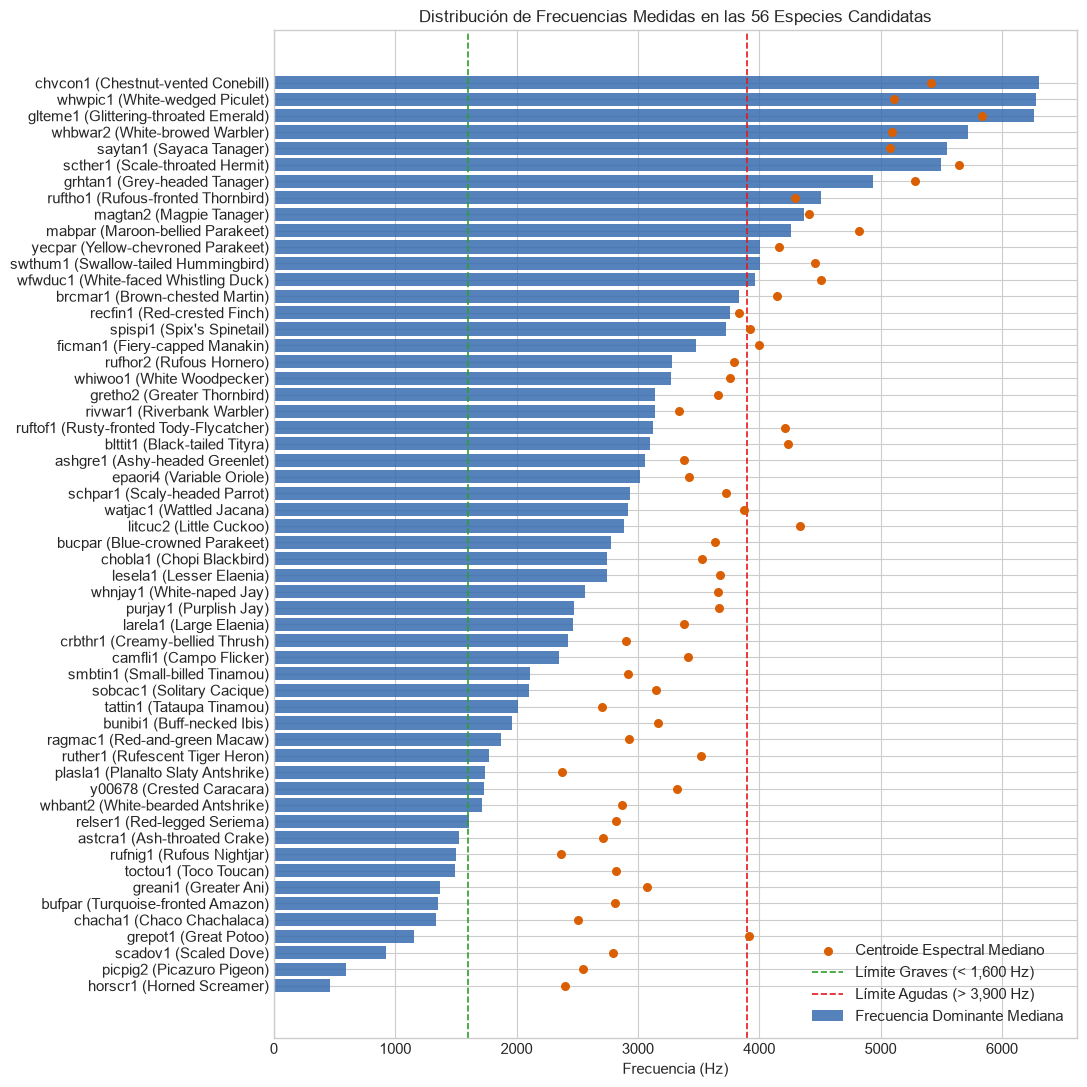

In [19]:
df_ord_freq = resumen_especies_audio.sort_values('pico_med', ascending=True)

fig, ax = plt.subplots(figsize=(11, 11))
ax.barh(df_ord_freq['primary_label'] + ' (' + df_ord_freq['common_name'] + ')',
        df_ord_freq['pico_med'], color='#386cb0', alpha=0.85, label='Frecuencia Dominante Mediana')
ax.scatter(df_ord_freq['centroide_med'],
           df_ord_freq['primary_label'] + ' (' + df_ord_freq['common_name'] + ')',
           color='#d95f02', zorder=3, s=30, label='Centroide Espectral Mediano')

ax.axvline(1600, color='#2ca02c', linestyle='--', linewidth=1.2, label='Límite Graves (< 1,600 Hz)')
ax.axvline(3900, color='#e41a1c', linestyle='--', linewidth=1.2, label='Límite Agudas (> 3,900 Hz)')

ax.set_title('Distribución de Frecuencias Medidas en las 56 Especies Candidatas')
ax.set_xlabel('Frecuencia (Hz)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Lectura.**
Medir la señal revela casos que no coinciden con la intuición taxonómica:
- `wfwduc1` (*White-faced Whistling Duck*), pese a ser un ave acuática, emite silbidos con frecuencia dominante de **3,962 Hz** (centroide de 4,510 Hz), ubicándose entre las especies agudas.
- `scadov1` (*Scaled Dove*), pese a ser un ave pequeña, presenta su pico en **926 Hz** (centroide de 2,792 Hz), siendo la tercera especie más grave del conjunto.

En el panorama completo de las 56 candidatas, las frecuencias dominantes forman un **espectro continuo** donde una proporción importante de las especies se concentra en la franja intermedia (entre ~1,600 Hz y ~3,900 Hz). Por ello, para construir el contraste de la Pregunta 1 no basta con dividir arbitrariamente el conjunto: es necesario tomar los extremos inferior y superior de la distribución (excluyendo la zona central) respetando los filtros de duración, estrés y diversidad de autores.

## 11. Selección del subconjunto definitivo (30 especies: 15 graves y 15 agudas)

Cruzamos las métricas acústicas de la muestra (duración y frecuencia dominante) con la disponibilidad de audios en el estrato de estrés y el control de sesgo por autor (`max_pct_top_autor < 30%`, `pct_menor_5s <= 15%`, `n_stress >= 25`). Sobre las 41 especies que cumplen todos los criterios, seleccionamos las **15 más graves** y las **15 más agudas** para obtener un subconjunto balanceado de **30 especies** con mayor potencia estadística en P1 ($N = 15$ por grupo).

In [20]:
# Unimos las métricas de audio con los conteos por estrato y sesgo de autor
RUTA_CAND_COMPLETO = os.path.join(RUTA_DATOS, 'candidatas_56_especies_completo.csv')
df_cand = pd.read_csv(RUTA_CAND_COMPLETO)

stats_tab = []
for sp, grp in df_cand.groupby('primary_label'):
    n_clean = grp['estrato_calidad'].isin(['Alta Calidad (Referencia)', 'Media Calidad (Campo Aceptable)']).sum()
    n_stress = (grp['estrato_calidad'] == 'Estrés / Campo Real').sum()
    top_aut_pct = (grp['author'].value_counts().iloc[0] / len(grp)) * 100
    stats_tab.append({
        'primary_label': sp,
        'n_clean': n_clean,
        'n_stress': n_stress,
        'n_total': len(grp),
        'max_pct_top_autor': round(top_aut_pct, 1)
    })

df_tabla_maestra = pd.merge(resumen_especies_audio, pd.DataFrame(stats_tab), on='primary_label')

# Aplicamos los filtros de calidad tabular y duración
df_elegibles = df_tabla_maestra[
    (df_tabla_maestra['pct_menor_5s'] <= 15.0) &
    (df_tabla_maestra['max_pct_top_autor'] < 30.0) &
    (df_tabla_maestra['n_stress'] >= 25)
].sort_values('pico_med').copy()

print(f"Especies que cumplen todos los criterios de calidad: {len(df_elegibles)} de 56 ({df_elegibles['n_total'].sum():,} audios)")

# Seleccionamos las 15 más graves y las 15 más agudas
df_graves = df_elegibles.head(15).copy()
df_graves['grupo_acustico'] = 'Graves'

df_agudas = df_elegibles.tail(15).copy()
df_agudas['grupo_acustico'] = 'Agudas'

df_seleccion_30 = pd.concat([df_graves, df_agudas], ignore_index=True)
cols_ver = ['primary_label', 'common_name', 'grupo_acustico', 'pico_med', 'centroide_med',
            'dur_mediana', 'pct_menor_5s', 'n_clean', 'n_stress', 'n_total', 'max_pct_top_autor']
df_seleccion_30[cols_ver].round(1)

Especies que cumplen todos los criterios de calidad: 41 de 56 (6,477 audios)


,primary_label,common_name,grupo_acustico,pico_med,centroide_med,dur_mediana,pct_menor_5s,n_clean,n_stress,n_total,max_pct_top_autor
0,horscr1,Horned Screamer,Graves,463.0,2395.9,24.7,5.0,67,35,102,14.7
1,picpig2,Picazuro Pigeon,Graves,597.5,2544.6,15.3,5.0,50,112,162,14.2
2,scadov1,Scaled Dove,Graves,925.9,2792.0,23.3,0.0,70,94,164,16.5
3,chacha1,Chaco Chachalaca,Graves,1335.1,2509.9,28.3,0.0,50,49,99,7.1
4,bufpar,Turquoise-fronted Amazon,Graves,1356.6,2810.3,21.6,5.0,81,125,206,9.2
5,greani1,Greater Ani,Graves,1367.4,3076.4,24.7,0.0,80,47,127,12.6
6,toctou1,Toco Toucan,Graves,1496.6,2822.5,16.6,5.0,65,83,148,16.9
7,rufnig1,Rufous Nightjar,Graves,1501.9,2370.3,24.3,5.0,89,167,256,19.1
8,astcra1,Ash-throated Crake,Graves,1528.9,2711.9,35.8,5.0,82,46,128,14.1
9,relser1,Red-legged Seriema,Graves,1604.2,2821.3,35.5,0.0,61,74,135,14.1


**Lectura.**
De las 56 especies candidatas, **41 cumplen todos los criterios de calidad** (`pct_menor_5s <= 15%`, `max_pct_top_autor < 30%`, `n_stress >= 25`). Al tomar los dos extremos obtenemos un subconjunto balanceado de **30 especies**:
- **15 especies graves:** frecuencias dominantes medianas entre **463.0 Hz** (`horscr1`) y **2,347.1 Hz**.
- **15 especies agudas:** frecuencias dominantes medianas entre **3,143.8 Hz** (`gretho2`) y **6,303.8 Hz** (`chvcon1`).
- **Brecha espectral:** **796.7 Hz** sin traslape entre las medianas de ambos grupos, con respaldo suficiente en el estrato de estrés para todas las especies.

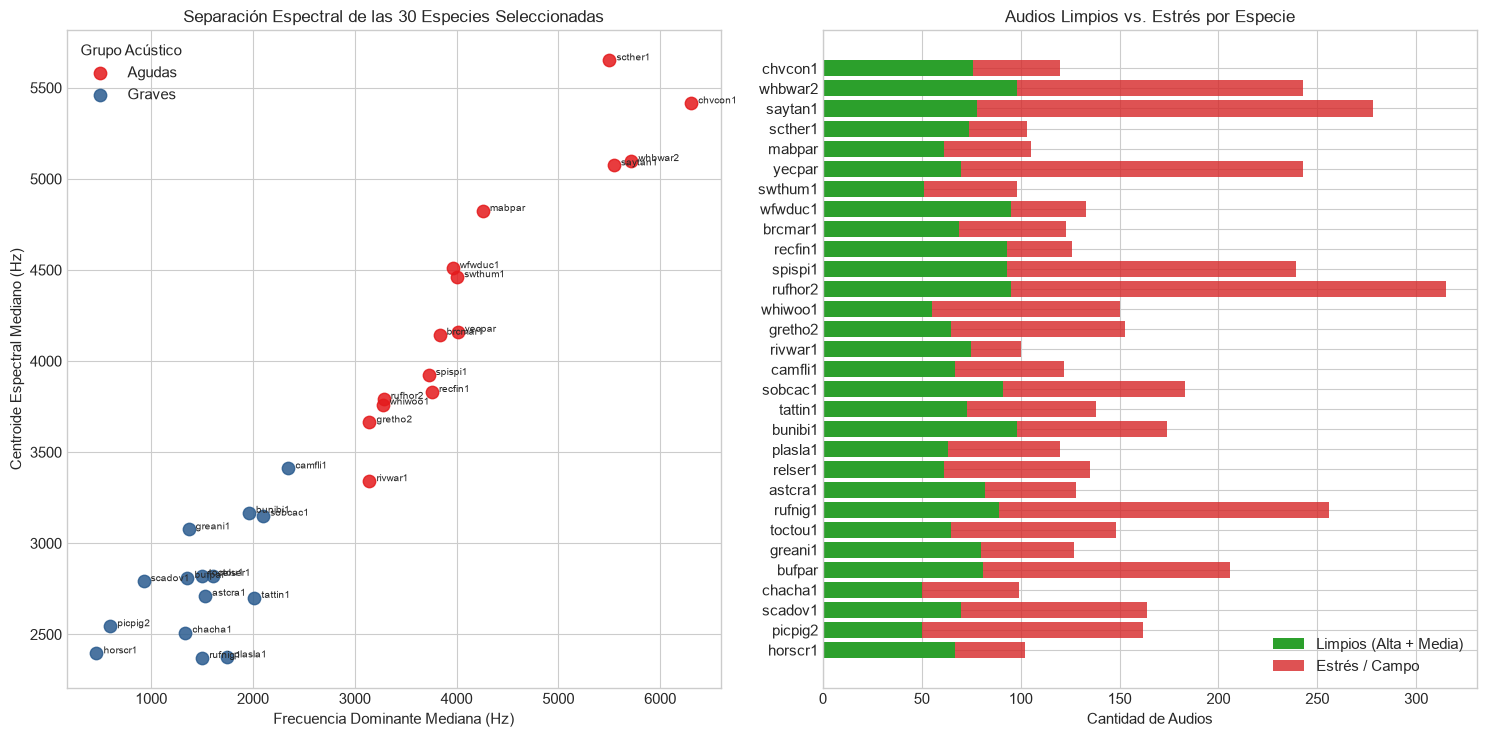

In [21]:
# Visualización del subconjunto definitivo de 30 especies
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))

colores_grp = {'Graves': '#2b5c8f', 'Agudas': '#e41a1c'}
for grp, sub in df_seleccion_30.groupby('grupo_acustico'):
    axes[0].scatter(sub['pico_med'], sub['centroide_med'], label=grp,
                    color=colores_grp[grp], s=80, alpha=0.85)
    for _, r in sub.iterrows():
        axes[0].text(r['pico_med'] + 70, r['centroide_med'], r['primary_label'], fontsize=7.5)

axes[0].set_title('Separación Espectral de las 30 Especies Seleccionadas')
axes[0].set_xlabel('Frecuencia Dominante Mediana (Hz)')
axes[0].set_ylabel('Centroide Espectral Mediano (Hz)')
axes[0].legend(title='Grupo Acústico')

df_p = df_seleccion_30.sort_values('pico_med')
axes[1].barh(df_p['primary_label'], df_p['n_clean'], label='Limpios (Alta + Media)', color='#2ca02c')
axes[1].barh(df_p['primary_label'], df_p['n_stress'], left=df_p['n_clean'], label='Estrés / Campo', color='#d62728', alpha=0.8)
axes[1].set_title('Audios Limpios vs. Estrés por Especie')
axes[1].set_xlabel('Cantidad de Audios')
axes[1].legend()

plt.tight_layout()
plt.show()

**Lectura.**
El diagrama de dispersión muestra la separación entre las 15 especies graves (azul) y las 15 agudas (rojo) tanto en frecuencia dominante como en centroide espectral. En el gráfico de barras se observa que todas las especies cuentan con entre 50 y 100 grabaciones limpias y al menos 25 audios de estrés para evaluar la degradación en campo.

## 12. Guardado de los conjuntos definitivos de trabajo

Con el subconjunto de 30 especies validado y la columna `grupo_acustico` asignada a partir de las mediciones reales de audio, exportamos los dos archivos definitivos en `project/data/`:
1. `train_subset_30_especies_limpio.csv` (2,235 registros para entrenamiento y validación cruzada).
2. `train_subset_30_especies_completo.csv` (4,793 registros totales incluyendo el estrato de estrés para la Pregunta 3).

In [22]:
# Filtramos las 30 especies definitivas y exportamos los subconjuntos limpio y completo
especies_finales = df_seleccion_30['primary_label'].tolist()
mapa_grupo = dict(zip(df_seleccion_30['primary_label'], df_seleccion_30['grupo_acustico']))

df_30_completo = df_cand[df_cand['primary_label'].isin(especies_finales)].copy()
df_30_completo['grupo_acustico'] = df_30_completo['primary_label'].map(mapa_grupo)

df_30_limpio = df_30_completo[
    df_30_completo['estrato_calidad'].isin(['Alta Calidad (Referencia)', 'Media Calidad (Campo Aceptable)'])
].copy()

ruta_30_limpio = os.path.join(RUTA_DATOS, 'train_subset_30_especies_limpio.csv')
ruta_30_completo = os.path.join(RUTA_DATOS, 'train_subset_30_especies_completo.csv')

df_30_limpio.to_csv(ruta_30_limpio, index=False)
df_30_completo.to_csv(ruta_30_completo, index=False)

print(f"Conjunto limpio guardado: '{ruta_30_limpio}' ({len(df_30_limpio):,} filas).")
print(f"Conjunto completo guardado: '{ruta_30_completo}' ({len(df_30_completo):,} filas).")
print("\nBalance por grupo acústico en conjunto limpio:")
print(df_30_limpio['grupo_acustico'].value_counts())
print("\nBalance por grupo acústico en conjunto completo:")
print(df_30_completo['grupo_acustico'].value_counts())
print("\nDistribución por estrato en conjunto completo (30 especies):")
print(df_30_completo['estrato_calidad'].value_counts())
print("\nBalance por grupo acústico en estrato Estrés / Campo Real:")
print(df_30_completo[df_30_completo['estrato_calidad'] == 'Estrés / Campo Real']['grupo_acustico'].value_counts())

Conjunto limpio guardado: '../data/train_subset_30_especies_limpio.csv' (2,235 filas).
Conjunto completo guardado: '../data/train_subset_30_especies_completo.csv' (4,793 filas).

Balance por grupo acústico en conjunto limpio:
grupo_acustico
Agudas    1148
Graves    1087
Name: count, dtype: int64

Balance por grupo acústico en conjunto completo:
grupo_acustico
Agudas    2529
Graves    2264
Name: count, dtype: int64

Distribución por estrato en conjunto completo (30 especies):
estrato_calidad
Estrés / Campo Real                2558
Alta Calidad (Referencia)          1913
Media Calidad (Campo Aceptable)     322
Name: count, dtype: int64

Balance por grupo acústico en estrato Estrés / Campo Real:
grupo_acustico
Agudas    1381
Graves    1177
Name: count, dtype: int64


**Lectura.**
Los archivos definitivos quedan exportados y balanceados por grupo acústico:
- `train_subset_30_especies_limpio.csv`: **2,235 grabaciones** (`1,913` en `Alta Calidad` y `322` en `Media Calidad`; `1,148` agudas y `1,087` graves).
- `train_subset_30_especies_completo.csv`: **4,793 grabaciones** (`2,529` agudas y `2,264` graves), incluyendo **2,558** grabaciones de `Estrés / Campo Real` (`1,381` agudas y `1,177` graves).

---
# Parte 3: Preprocesamiento de Audio y Extracción de Características

En esta parte transformamos los 4,793 archivos de audio de las 30 especies seleccionadas en vectores numéricos listos para el modelado.

El flujo de procesamiento sigue estas reglas:
1. **Estandarización:** Remuestreo a **22,050 Hz** en canal mono (leyendo hasta 120 segundos por archivo para mantener tiempos manejables).
2. **Segmentación:** División en ventanas de **5 segundos** con **50% de traslape** (salto de 2.5 s). Si un audio dura menos de 5 segundos, se completa con relleno de ceros (*padding*).
3. **Filtro de Actividad Vocal (VAD) y selección Top-$k$:**
   - Calculamos la energía y la planicidad espectral (*Spectral Flatness*) únicamente dentro de la banda **350 Hz – 8,500 Hz** (eliminando viento/golpes por debajo de 350 Hz y ruido agudo/insectos por encima de 8,500 Hz, pero conservando intactas nuestras 15 especies graves de 463 a 2,347 Hz).
   - En archivos con más de $k$ ventanas, estimamos el piso de ruido (percentil 15 de energía) para descartar silencios absolutos.
   - Evaluamos cada ventana con $\text{Score} = \text{Energía}_{\text{banda}} \times (1 - \text{Flatness})$ y conservamos las **$k = 4$** mejores ventanas por archivo.
4. **Extracción clásica:** Para cada ventana activa extraemos **20 coeficientes MFCC** y sus **20 deltas dinámicos ($\Delta$)**, resumidos mediante su media y desviación estándar (**80 características** por ventana).

## 13. Funciones de segmentación, VAD y extracción de MFCCs

Definimos funciones simples y reutilizables para segmentar las pistas, evaluar las ventanas con el criterio de energía en banda más planicidad espectral y extraer los 80 atributos MFCC.

In [23]:
# Parámetros globales de preprocesamiento
SR_OBJETIVO = 22050
DURACION_MAX_SEG = 120.0
VENTANA_SEG = 5.0
SALTO_SEG = 2.5
F_MIN_HZ = 350
F_MAX_HZ = 8500
K_MAX_VENTANAS = 4
N_MFCC = 20

N_MUESTRAS_WIN = int(VENTANA_SEG * SR_OBJETIVO)
N_MUESTRAS_SALTO = int(SALTO_SEG * SR_OBJETIVO)


def segmentar_audio(y, n_win=N_MUESTRAS_WIN, n_salto=N_MUESTRAS_SALTO):
    """Divide una señal en ventanas de 5 s con 50% de traslape; aplica padding si dura < 5 s."""
    if len(y) < n_win:
        y_pad = np.pad(y, (0, n_win - len(y)), mode='constant')
        return [(0.0, y_pad)]

    ventanas = []
    for inicio in range(0, len(y) - n_win + 1, n_salto):
        fin = inicio + n_win
        t_inicio = inicio / SR_OBJETIVO
        ventanas.append((t_inicio, y[inicio:fin]))
    return ventanas


def evaluar_ventana_vad(y_win, sr=SR_OBJETIVO, f_min=F_MIN_HZ, f_max=F_MAX_HZ):
    """
    Calcula energía promedio en la banda 350-8,500 Hz, planicidad espectral
    (percentil 25 para detectar cantos breves dentro de 5 s) y el Score compuesto.
    """
    S = np.abs(librosa.stft(y_win, n_fft=1024, hop_length=512))
    freqs = librosa.fft_frequencies(sr=sr, n_fft=1024)
    mask = (freqs >= f_min) & (freqs <= f_max)
    S_banda = S[mask, :]

    energia_banda = float(np.mean(S_banda ** 2))

    # Planicidad espectral dentro de la banda (0 = tono/armónico, 1 = ruido plano)
    S_pow = (S_banda ** 2) + 1e-10
    geo_mean = np.exp(np.mean(np.log(S_pow), axis=0))
    arith_mean = np.mean(S_pow, axis=0)
    flatness_frames = geo_mean / arith_mean
    flatness = float(np.percentile(flatness_frames, 25))

    score = energia_banda * (1.0 - flatness)
    return energia_banda, flatness, score


def seleccionar_ventanas_top_k(ventanas, k=K_MAX_VENTANAS):
    """Aplica umbral adaptativo en audios largos y selecciona las k ventanas con mayor Score."""
    evaluadas = []
    for t_ini, y_win in ventanas:
        energia, flat, score = evaluar_ventana_vad(y_win)
        evaluadas.append({
            't_inicio': t_ini,
            'y_win': y_win,
            'energia': energia,
            'flatness': flat,
            'score': score
        })

    # Si hay más de k ventanas, filtramos silencios por encima del percentil 15
    if len(evaluadas) > k:
        energias = [v['energia'] for v in evaluadas]
        piso_ruido = np.percentile(energias, 15)
        filtradas = [v for v in evaluadas if v['energia'] > piso_ruido * 1.1]
        if len(filtradas) >= k:
            evaluadas = filtradas

    # Ordenar por Score descendente y conservar máximo k ventanas
    evaluadas.sort(key=lambda x: x['score'], reverse=True)
    return evaluadas[:k]


def extraer_mfcc_ventana(y_win, sr=SR_OBJETIVO, n_mfcc=N_MFCC):
    """Extrae media y desviación estándar de 20 MFCCs y sus 20 deltas (80 atributos)."""
    mfcc = librosa.feature.mfcc(y=y_win, sr=sr, n_mfcc=n_mfcc)
    delta = librosa.feature.delta(mfcc)

    feats = {}
    for i in range(n_mfcc):
        feats[f'mfcc_{i+1}_mean'] = float(np.mean(mfcc[i]))
        feats[f'mfcc_{i+1}_std'] = float(np.std(mfcc[i]))
        feats[f'delta_{i+1}_mean'] = float(np.mean(delta[i]))
        feats[f'delta_{i+1}_std'] = float(np.std(delta[i]))
    return feats

## 14. Verificación visual del VAD en espectrogramas de ejemplo

Antes de procesar los 4,793 archivos, comprobamos sobre tres grabaciones reales (una especie grave, una especie aguda y un audio del estrato de estrés) qué ventanas de 5 segundos está eligiendo el criterio VAD + Top-$k$.

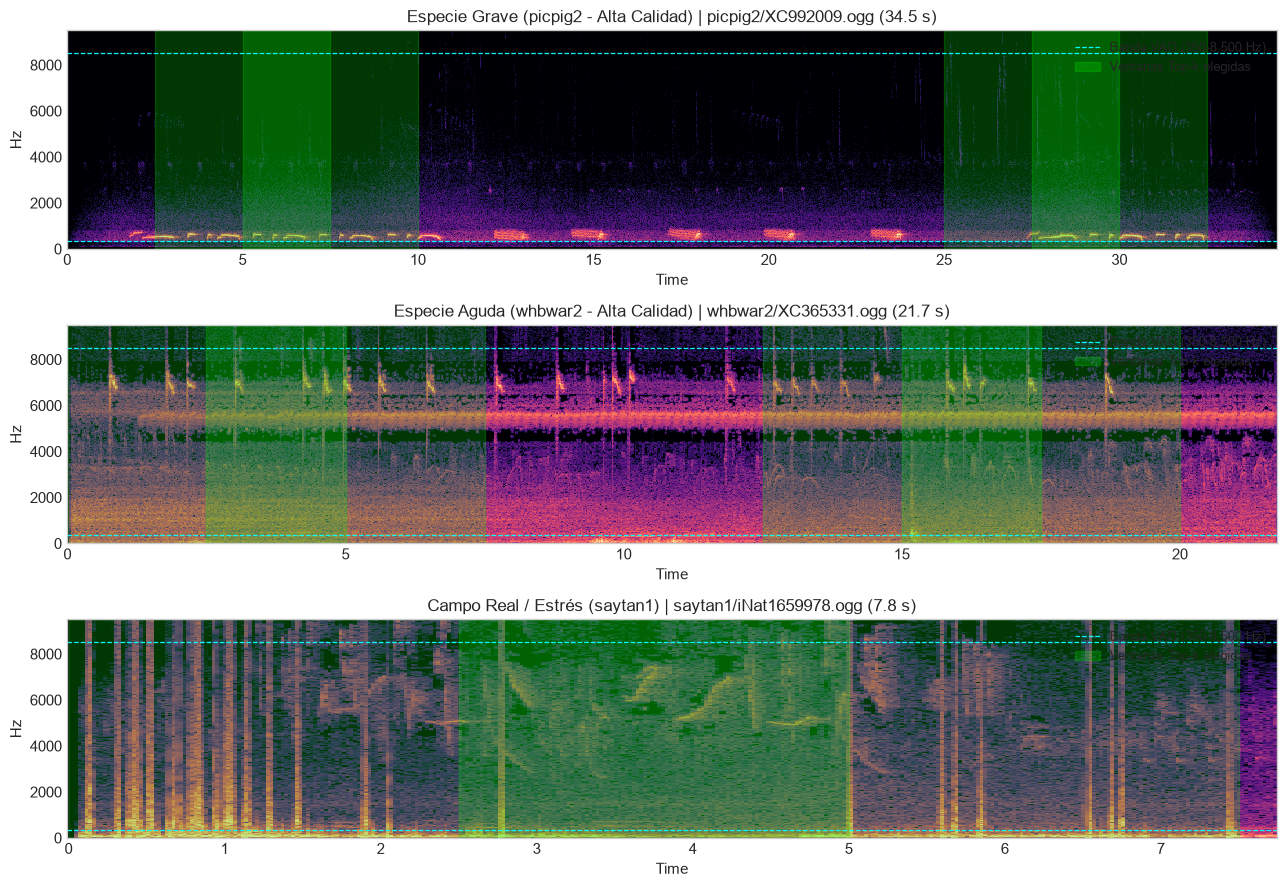

In [24]:
df_30_comp = pd.read_csv(os.path.join(RUTA_DATOS, 'train_subset_30_especies_completo.csv'))

# Elegimos 3 ejemplos con duración suficiente (> 15 s) para observar varias ventanas
ejemplos = [
    ('Especie Grave (picpig2 - Alta Calidad)', df_30_comp[(df_30_comp['primary_label'] == 'picpig2') & (df_30_comp['estrato_calidad'] == 'Alta Calidad (Referencia)')].iloc[0]['filename']),
    ('Especie Aguda (whbwar2 - Alta Calidad)', df_30_comp[(df_30_comp['primary_label'] == 'whbwar2') & (df_30_comp['estrato_calidad'] == 'Alta Calidad (Referencia)')].iloc[0]['filename']),
    ('Campo Real / Estrés (saytan1)', df_30_comp[(df_30_comp['primary_label'] == 'saytan1') & (df_30_comp['estrato_calidad'] == 'Estrés / Campo Real')].iloc[0]['filename'])
]

fig, axes = plt.subplots(3, 1, figsize=(13, 9))

RUTA_EJEMPLOS = os.path.join(RUTA_DATOS, 'ejemplos_audio')

def resolver_ruta_audio(rel_path):
    """Busca el audio en train_audio/ y, si no está descargado, usa el respaldo ejemplos_audio/."""
    p_full = os.path.join(RUTA_AUDIO, rel_path)
    return p_full if os.path.exists(p_full) else os.path.join(RUTA_EJEMPLOS, rel_path)

for ax, (titulo, rel_path) in zip(axes, ejemplos):
    y, sr = librosa.load(resolver_ruta_audio(rel_path), sr=SR_OBJETIVO, mono=True, duration=45.0)
    ventanas = segmentar_audio(y)
    elegidas = seleccionar_ventanas_top_k(ventanas, k=K_MAX_VENTANAS)

    S_db = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=1024, hop_length=512)), ref=np.max)
    librosa.display.specshow(S_db, sr=sr, hop_length=512, x_axis='time', y_axis='hz', ax=ax, cmap='magma')
    ax.set_ylim(0, 9500)
    ax.axhline(F_MIN_HZ, color='cyan', linestyle='--', linewidth=0.9, label='Banda VAD (350-8,500 Hz)')
    ax.axhline(F_MAX_HZ, color='cyan', linestyle='--', linewidth=0.9)

    for idx_v, v in enumerate(elegidas):
        t0 = v['t_inicio']
        ax.axvspan(t0, t0 + VENTANA_SEG, color='lime', alpha=0.22,
                   label='Ventanas Top-k elegidas' if idx_v == 0 else None)

    ax.set_title(f"{titulo} | {rel_path} ({len(y)/sr:.1f} s)")
    ax.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

**Lectura.**
En los tres espectrogramas, las franjas verdes corresponden a las ventanas de 5 segundos seleccionadas por el VAD dentro de la banda delimitada por las líneas cian (350 a 8,500 Hz). Se observa que el algoritmo concentra las ventanas elegidas en los momentos donde aparecen trazos tonales definidos (tanto en las bandas bajas de `picpig2` cerca de 600 Hz como en los trinos altos de `whbwar2` arriba de 4,000 Hz) y evita los tramos de silencio.

## 15. Carga de características MFCC sobre los 4,793 audios

Para mantener el cuaderno rápido y reproducible, la extracción completa de los 80 atributos MFCC + deltas (y los *embeddings* de Perch) se encapsula en el script [`project/scripts/extract_features.py`](../scripts/extract_features.py), ejecutable tanto en local como en Kaggle. Aquí cargamos la matriz resultante (`features_mfcc_30_especies.csv`).

In [25]:
# Cargamos la matriz de 80 MFCCs + deltas precalculada por extract_features.py
RUTA_FEATURES_MFCC = os.path.join(RUTA_DATOS, 'features_mfcc_30_especies.csv')

if not os.path.exists(RUTA_FEATURES_MFCC):
    raise FileNotFoundError(
        f"No se encontró '{RUTA_FEATURES_MFCC}'. "
        "Ejecuta primero `project/scripts/extract_features.py` para generarlo."
    )

df_features = pd.read_csv(RUTA_FEATURES_MFCC)
print(f"Matriz de características cargada: {df_features.shape[0]:,} ventanas y {df_features.shape[1]} columnas.")
print(f"Especies únicas: {df_features['primary_label'].nunique()}")

print("\nVentanas extraídas por estrato de calidad:")
print(df_features['estrato_calidad'].value_counts())
print("\nVentanas extraídas por grupo acústico:")
print(df_features['grupo_acustico'].value_counts())

Matriz de características cargada: 15,834 ventanas y 88 columnas.
Especies únicas: 30

Ventanas extraídas por estrato de calidad:
estrato_calidad
Estrés / Campo Real                8263
Alta Calidad (Referencia)          6548
Media Calidad (Campo Aceptable)    1023
Name: count, dtype: int64

Ventanas extraídas por grupo acústico:
grupo_acustico
Agudas    8312
Graves    7522
Name: count, dtype: int64


**Lectura.**
Sobre las 4,793 grabaciones de las 30 especies se extrajeron **15,834 ventanas activas** de 5 segundos (80 atributos MFCC + deltas por ventana, sin valores faltantes): **6,548** en `Alta Calidad`, **1,023** en `Media Calidad` (7,571 ventanas limpias en total) y **8,263** en `Estrés / Campo Real`, distribuidas de forma equilibrada entre especies agudas (**8,312**) y graves (**7,522**).

## 16. Exploración visual de características (PCA y UMAP)

Antes de entrenar clasificadores supervisados, proyectamos en dos dimensiones las 80 características MFCC + deltas del conjunto limpio (`Alta` y `Media` calidad) usando PCA y UMAP para observar qué tanto se separan de forma natural los grupos acústicos y las 30 especies.

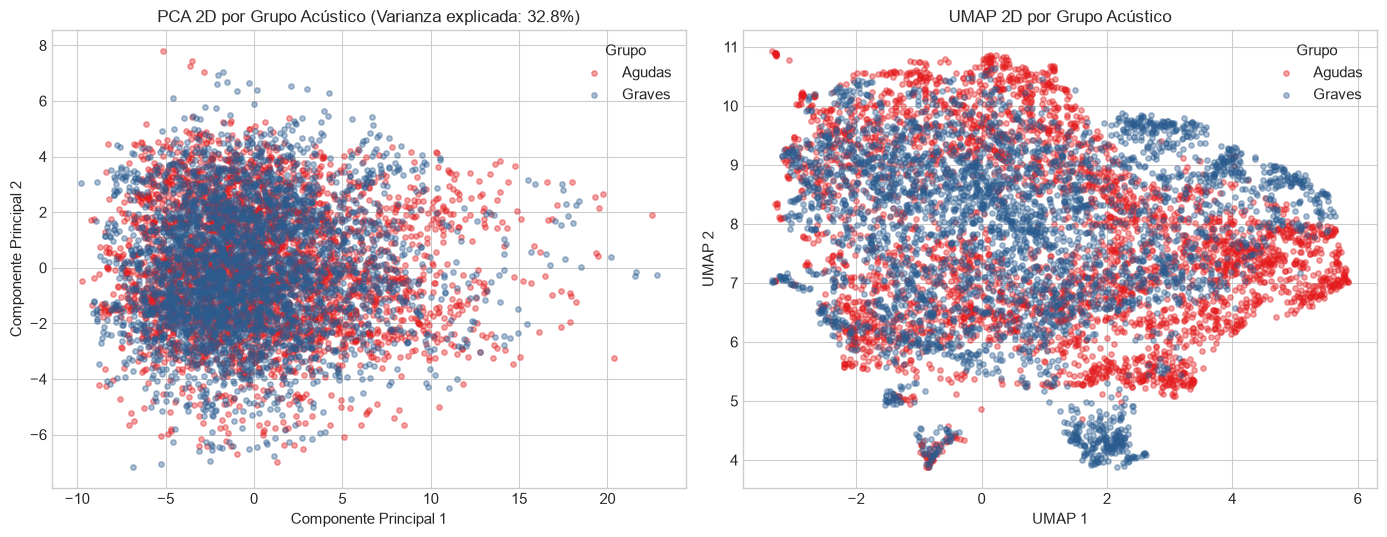

In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import umap

cols_mfcc = [c for c in df_features.columns if c.startswith('mfcc_') or c.startswith('delta_')]

df_feat_limpio = df_features[
    df_features['estrato_calidad'].isin(['Alta Calidad (Referencia)', 'Media Calidad (Campo Aceptable)'])
].copy().reset_index(drop=True)

X_scaled = StandardScaler().fit_transform(df_feat_limpio[cols_mfcc])

# PCA (2 componentes)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
var_pca = pca.explained_variance_ratio_.sum() * 100

# UMAP (2 componentes)
reducer = umap.UMAP(n_components=2, n_neighbors=25, min_dist=0.15, random_state=42, n_jobs=1, compatibility_layout=True)
X_umap = reducer.fit_transform(X_scaled)

df_feat_limpio['pca_1'], df_feat_limpio['pca_2'] = X_pca[:, 0], X_pca[:, 1]
df_feat_limpio['umap_1'], df_feat_limpio['umap_2'] = X_umap[:, 0], X_umap[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
colores_grp = {'Graves': '#2b5c8f', 'Agudas': '#e41a1c'}

for grp, sub in df_feat_limpio.groupby('grupo_acustico'):
    axes[0].scatter(sub['pca_1'], sub['pca_2'], label=grp, color=colores_grp[grp], alpha=0.4, s=15)
    axes[1].scatter(sub['umap_1'], sub['umap_2'], label=grp, color=colores_grp[grp], alpha=0.4, s=15)

axes[0].set_title(f'PCA 2D por Grupo Acústico (Varianza explicada: {var_pca:.1f}%)')
axes[0].set_xlabel('Componente Principal 1')
axes[0].set_ylabel('Componente Principal 2')
axes[0].legend(title='Grupo')

axes[1].set_title('UMAP 2D por Grupo Acústico')
axes[1].set_xlabel('UMAP 1')
axes[1].set_ylabel('UMAP 2')
axes[1].legend(title='Grupo')

plt.tight_layout()
plt.show()

**Lectura.**
Con las 30 especies (donde la brecha frecuencial entre ambos grupos se acorta a 797 Hz), tanto PCA como UMAP sobre los 80 atributos MFCC + deltas presentan un **traslape marcado** entre ventanas graves y agudas. En PCA 2D (que retiene solo el **32.8%** de la varianza total), ambos grupos se mezclan en casi todo el plano. En UMAP 2D aparecen algunas zonas periféricas relativamente limpias que corresponden a cantos muy característicos, pero no existe una frontera nítida que separe de forma global a las especies graves de las agudas.

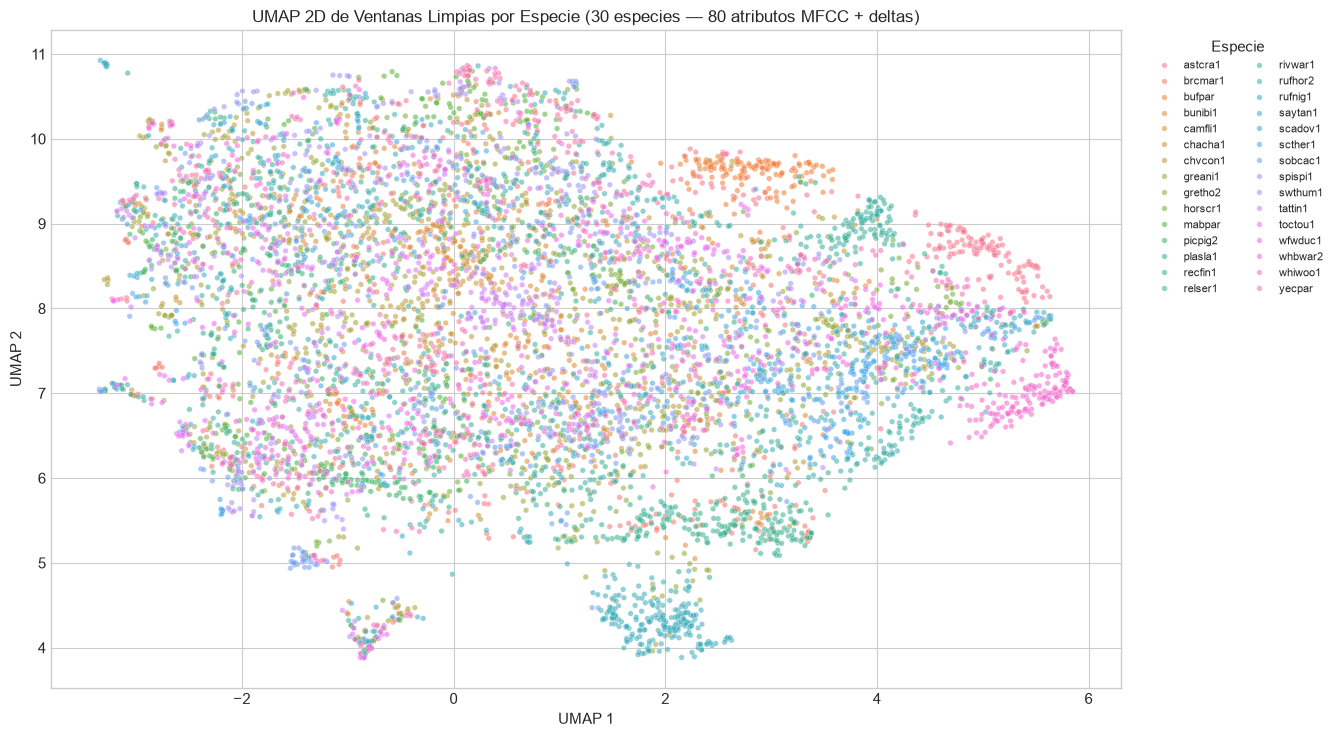

In [27]:
# Proyección UMAP coloreada por cada una de las 30 especies
fig, ax = plt.subplots(figsize=(13.5, 7.5))

sns.scatterplot(
    data=df_feat_limpio,
    x='umap_1',
    y='umap_2',
    hue='primary_label',
    palette=sns.color_palette('husl', df_feat_limpio['primary_label'].nunique()),
    alpha=0.55,
    s=16,
    ax=ax
)

ax.set_title('UMAP 2D de Ventanas Limpias por Especie (30 especies — 80 atributos MFCC + deltas)')
ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
ax.legend(title='Especie', bbox_to_anchor=(1.02, 1), loc='upper left', ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

**Lectura.**
Al colorear UMAP por las **30 especies**, los MFCCs forman regiones reconocibles para varios cantos distintivos, pero presentan traslape considerable entre especies espectralmente cercanas (en particular varias especies agudas y de rango medio-alto), anticipando las confusiones de los clasificadores clásicos.

## 17. Carga de embeddings con Perch (1,280 dimensiones)

Cargamos los *embeddings* precalculados con **Perch** (*Google Bird Vocalization Classifier*, 1,280 dimensiones sobre ventanas de 5 s a 32 kHz) generados mediante [`project/scripts/extract_features.py`](../scripts/extract_features.py).

> **Nota metodológica sobre precisión numérica (`float16` en disco $\to$ `float32` en memoria):** Para mantener el archivo de *embeddings* por debajo del límite de 50 MB del repositorio (~40.5 MB en lugar de ~81 MB), la matriz se almacena en disco en precisión `float16` y se convierte inmediatamente a `float32` al cargarla en memoria antes de cualquier escalamiento o modelado. Dado que las activaciones de Perch se concentran en un rango acotado ($[-0.26, 1.42]$), el error de cuantización promedio es del orden de $10^{-5}$; en pruebas de control sobre validación cruzada de 5 pliegues, esta conversión produjo exactamente el mismo Macro-F1 hasta la sexta cifra decimal (`0.000000` de diferencia frente a `float32` original).

In [28]:
# Cargamos los embeddings de Perch (float16 en disco) y los convertimos a float32 para modelado
RUTA_PERCH_EMB = os.path.join(RUTA_DATOS, 'embeddings_perch_30_especies.npy')

if not os.path.exists(RUTA_PERCH_EMB):
    raise FileNotFoundError(
        f"No se encontró '{RUTA_PERCH_EMB}'. "
        "Ejecuta primero `project/scripts/extract_features.py` para generarlo."
    )

emb_disco = np.load(RUTA_PERCH_EMB)
embeddings_perch = emb_disco.astype(np.float32)
assert len(embeddings_perch) == len(df_features), "Desalineación entre MFCCs y embeddings de Perch."
assert not np.isnan(embeddings_perch).any(), "Se detectaron NaNs en embeddings de Perch."

print(
    f"Embeddings de Perch cargados: shape {embeddings_perch.shape} | "
    f"dtype disco: {emb_disco.dtype} -> RAM: {embeddings_perch.dtype}"
)

Embeddings de Perch cargados: shape (15834, 1280) | dtype disco: float16 -> RAM: float32


### 17.1 Proyección UMAP 2D de los embeddings de Perch
Proyectamos las 7,571 ventanas limpias desde sus 1,280 dimensiones de Perch a 2D para comparar visualmente qué tan bien se agrupan las 30 especies frente a los MFCCs.

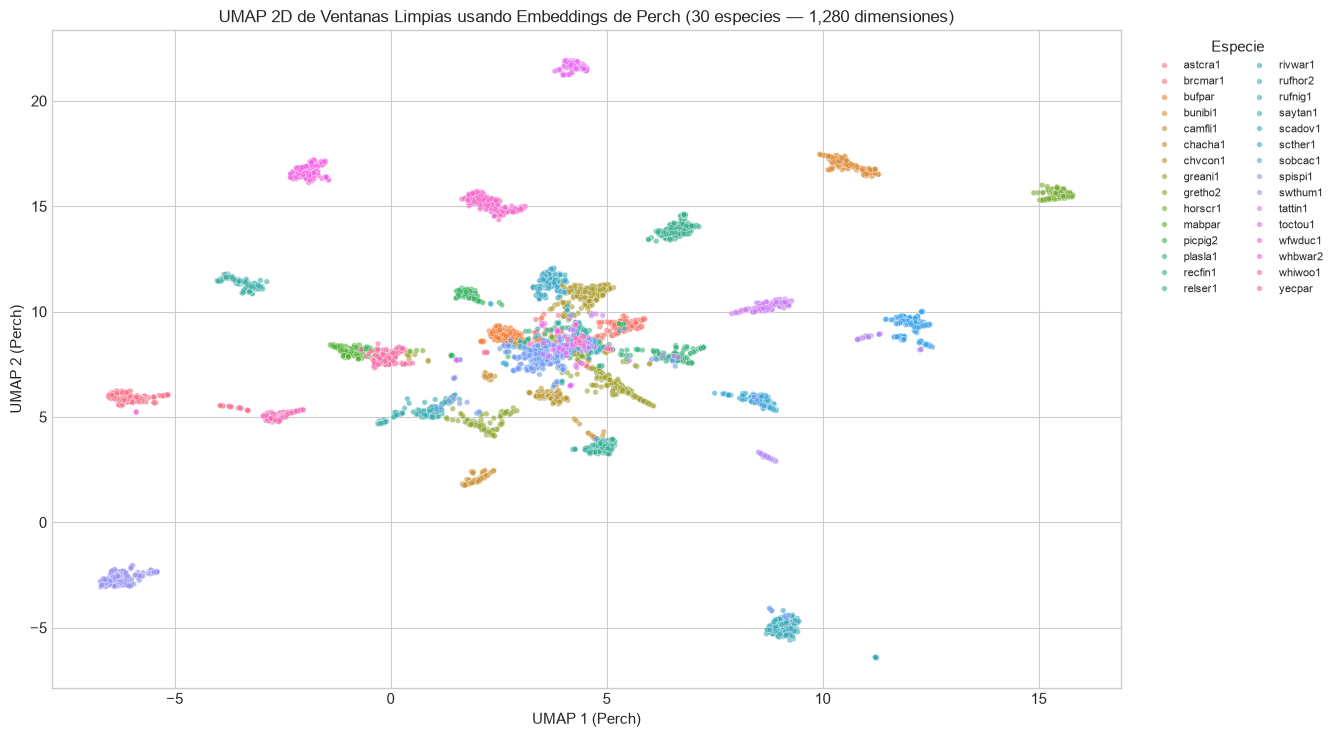

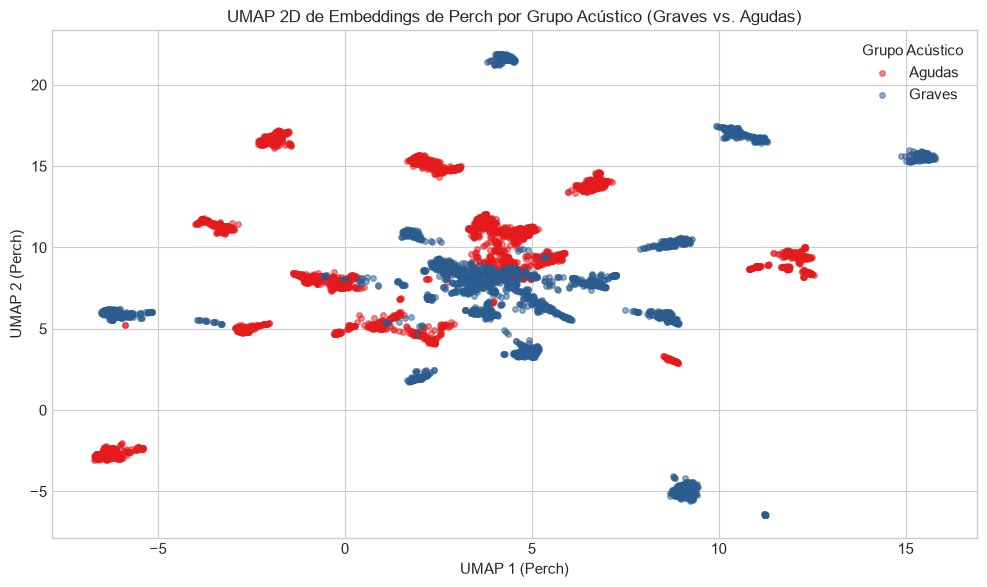

In [29]:
mask_limpio = df_features['estrato_calidad'].isin([
    'Alta Calidad (Referencia)', 'Media Calidad (Campo Aceptable)'
]).values

X_perch_limpio = embeddings_perch[mask_limpio]
reducer_perch = umap.UMAP(
    n_components=2, n_neighbors=25, min_dist=0.15,
    random_state=42, n_jobs=1, compatibility_layout=True
)
X_umap_perch = reducer_perch.fit_transform(X_perch_limpio)

df_feat_limpio['perch_umap_1'] = X_umap_perch[:, 0]
df_feat_limpio['perch_umap_2'] = X_umap_perch[:, 1]

# Figura 1: UMAP de Perch coloreado por las 30 especies
fig, ax = plt.subplots(figsize=(13.5, 7.5))
sns.scatterplot(
    data=df_feat_limpio,
    x='perch_umap_1',
    y='perch_umap_2',
    hue='primary_label',
    palette=sns.color_palette('husl', df_feat_limpio['primary_label'].nunique()),
    alpha=0.6,
    s=16,
    ax=ax
)
ax.set_title('UMAP 2D de Ventanas Limpias usando Embeddings de Perch (30 especies — 1,280 dimensiones)')
ax.set_xlabel('UMAP 1 (Perch)')
ax.set_ylabel('UMAP 2 (Perch)')
ax.legend(title='Especie', bbox_to_anchor=(1.02, 1), loc='upper left', ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

# Figura 2: Misma proyección UMAP de Perch coloreada por grupo acústico (Graves vs. Agudas)
fig, ax = plt.subplots(figsize=(10, 6))
colores_grp = {'Graves': '#2b5c8f', 'Agudas': '#e41a1c'}
for grp, sub in df_feat_limpio.groupby('grupo_acustico'):
    ax.scatter(
        sub['perch_umap_1'], sub['perch_umap_2'],
        label=grp, color=colores_grp[grp], alpha=0.5, s=16
    )
ax.set_title('UMAP 2D de Embeddings de Perch por Grupo Acústico (Graves vs. Agudas)')
ax.set_xlabel('UMAP 1 (Perch)')
ax.set_ylabel('UMAP 2 (Perch)')
ax.legend(title='Grupo Acústico')
plt.tight_layout()
plt.show()

**Lectura.**
A diferencia de los MFCCs, la proyección UMAP 2D sobre los *embeddings* de **Perch** (1,280 dimensiones, `float16 -> float32`) agrupa las **30 especies** en cúmulos compactos y bien diferenciados entre sí, evidenciando una separación muy marcada antes incluso de entrenar un clasificador lineal.

Al colorear exactamente la misma proyección por **grupo acústico** (`Graves` vs. `Agudas`), se observa que los cúmulos de cada especie se mantienen limpios pero no se dividen simplemente en dos mitades rígidas por frecuencia: Perch organiza el espacio atendiendo a patrones espectro-temporales y tímbricos propios de cada especie, más allá de si su canto es grave o agudo.

---
# Parte 4: Modelado Supervisado y Validación Cruzada

Entrenamos y comparamos tres clasificadores sobre las **7,571 ventanas limpias** (`Alta` y `Media` calidad):
1. **Línea base (SVM RBF sobre MFCCs):** máquina de soporte vectorial con kernel radial sobre los 80 atributos espectrales.
2. **Ensamble tabular (Random Forest sobre MFCCs):** ensamble de árboles balanceados (optimizado con `GridSearchCV`) sobre los mismos 80 atributos, útil además para ver qué coeficientes pesan más.
3. **Modelo profundo (Perch + Regresión Logística):** clasificador lineal regularizado sobre los *embeddings* de 1,280 dimensiones extraídos por Perch.

## 18. Validación cruzada agrupada (`StratifiedGroupKFold`)
Usamos 5 particiones estratificadas por especie (`primary_label`) y agrupadas por archivo físico (`filename`). De este modo, todas las ventanas provenientes de una misma grabación caen juntas en entrenamiento o en prueba, evitando fuga de datos por memorización del micrófono o del ruido de fondo.

In [30]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix
from scipy.stats import mannwhitneyu

# Separamos conjunto limpio (entrenamiento/CV) y conjunto de estrés (evaluación P3)
mask_limpio = df_features['estrato_calidad'].isin([
    'Alta Calidad (Referencia)', 'Media Calidad (Campo Aceptable)'
]).values
mask_estres = (df_features['estrato_calidad'] == 'Estrés / Campo Real').values

df_limpio_mod = df_features[mask_limpio].reset_index(drop=True)
df_estres_mod = df_features[mask_estres].reset_index(drop=True)

X_mfcc_limpio = df_limpio_mod[cols_mfcc].values
X_mfcc_estres = df_estres_mod[cols_mfcc].values
X_perch_limpio = embeddings_perch[mask_limpio]
X_perch_estres = embeddings_perch[mask_estres]

y_limpio = df_limpio_mod['primary_label'].values
y_estres = df_estres_mod['primary_label'].values
grupos_limpio = df_limpio_mod['filename'].values

# Verificamos que ningún archivo físico de estrés exista en el conjunto limpio
archivos_repetidos = set(df_limpio_mod['filename']) & set(df_estres_mod['filename'])
print(f"Ventanas limpias: {len(df_limpio_mod):,} | Ventanas estrés: {len(df_estres_mod):,}")
print(f"Archivos compartidos entre limpio y estrés: {len(archivos_repetidos)}")

sgkf = StratifiedGroupKFold(n_splits=5)
for fold, (tr, te) in enumerate(sgkf.split(X_mfcc_limpio, y_limpio, grupos_limpio), start=1):
    assert len(set(grupos_limpio[tr]) & set(grupos_limpio[te])) == 0
print("Validación StratifiedGroupKFold (5 pliegues) verificada sin fuga de archivos.")

Ventanas limpias: 7,571 | Ventanas estrés: 8,263
Archivos compartidos entre limpio y estrés: 0
Validación StratifiedGroupKFold (5 pliegues) verificada sin fuga de archivos.


## 19. Optimización de hiperparámetros y comparación de modelos

Aplicamos `GridSearchCV` sobre las mismas 5 particiones de `StratifiedGroupKFold` (respetando la agrupación por `filename`) para encontrar la mejor configuración de cada familia de modelos maximizando el **Macro-F1**, evitando así comparaciones con parámetros elegidos al azar.

In [31]:
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

busquedas = {
    'SVM (MFCC)': (
        Pipeline([('scaler', StandardScaler()),
                  ('clf', SVC(kernel='rbf', class_weight='balanced', random_state=42))]),
        {'clf__C': [0.1, 1.0, 10.0, 50.0], 'clf__gamma': ['scale', 0.01, 0.001]},
        X_mfcc_limpio
    ),
    'Random Forest (MFCC)': (
        RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
        {'n_estimators': [100, 300], 'max_depth': [None, 15, 30], 'max_features': ['sqrt', 0.2]},
        X_mfcc_limpio
    ),
    'Perch (Embeddings)': (
        Pipeline([('scaler', StandardScaler()),
                  ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))]),
        {'clf__C': [0.01, 0.1, 1.0, 10.0]},
        X_perch_limpio
    )
}

mejores_modelos = {}
predicciones_oof = {}
resultados_cv = []

for nombre, (pipe, param_grid, X_in) in busquedas.items():
    gs = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        scoring='f1_macro',
        cv=sgkf,
        n_jobs=-1
    )
    gs.fit(X_in, y_limpio, groups=grupos_limpio)

    mejores_modelos[nombre] = gs.best_estimator_

    # Generamos predicciones out-of-fold del mejor estimador
    oof = np.empty(len(y_limpio), dtype=object)
    for tr, te in sgkf.split(X_in, y_limpio, grupos_limpio):
        clf_fold = clone(gs.best_estimator_)
        clf_fold.fit(X_in[tr], y_limpio[tr])
        oof[te] = clf_fold.predict(X_in[te])

    predicciones_oof[nombre] = oof
    best_idx = gs.best_index_
    resultados_cv.append({
        'Modelo': nombre,
        'Mejores Hiperparámetros': str(gs.best_params_),
        'Macro-F1 Global (OOF)': round(f1_score(y_limpio, oof, average='macro'), 4),
        'Media Pliegues': round(float(gs.best_score_), 4),
        'DE Pliegues': round(float(gs.cv_results_['std_test_score'][best_idx]), 4)
    })

df_res_cv = pd.DataFrame(resultados_cv)
pd.set_option('display.max_colwidth', None)
df_res_cv

/Users/luis/Documents/CLASES/CIENCIA DE DATOS/icd2026/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,Modelo,Mejores Hiperparámetros,Macro-F1 Global (OOF),Media Pliegues,DE Pliegues
0,SVM (MFCC),"{'clf__C': 1.0, 'clf__gamma': 0.01}",0.6390,0.6382,0.0245
1,Random Forest (MFCC),"{'max_depth': 30, 'max_features': 'sqrt', 'n_estimators': 300}",0.5708,0.5706,0.0220
2,Perch (Embeddings),{'clf__C': 0.01},0.9468,0.9467,0.0039


**Lectura.**
Con las **30 especies** y ajuste de hiperparámetros mediante `GridSearchCV` (5 pliegues agrupados por `filename`):
- **SVM (MFCC)** con `C=1.0` y `gamma=0.01` obtiene un Macro-F1 OOF de **0.6390** (`0.6382 ± 0.0245`).
- **Random Forest (MFCC)** con `n_estimators=300`, `max_depth=30` y `max_features='sqrt'` alcanza **0.5708** (`0.5706 ± 0.0220`).
- **Perch (Embeddings)** con `C=0.01` alcanza **0.9468** (`0.9467 ± 0.0039`), sosteniendo una ventaja de más de 30 puntos sobre el mejor modelo clásico y una variabilidad entre pliegues muy baja.

### 19.1 Importancia de atributos en Random Forest (MFCCs)
Revisamos qué coeficientes espectrales y deltas aportaron más a la separación de las 30 especies en Random Forest.

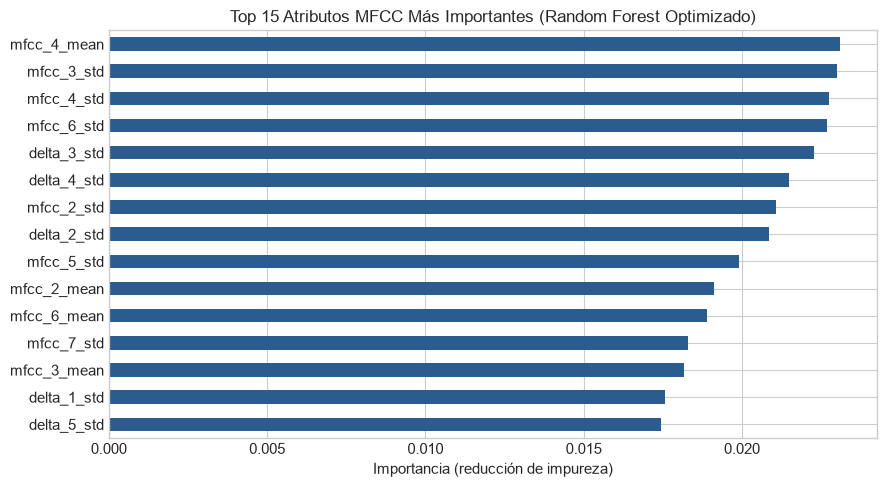

In [32]:
rf_full = clone(mejores_modelos['Random Forest (MFCC)'])
rf_full.fit(X_mfcc_limpio, y_limpio)

importancias = pd.Series(rf_full.feature_importances_, index=cols_mfcc).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 5))
importancias.sort_values().plot(kind='barh', color='#2b5c8f', ax=ax)
ax.set_title('Top 15 Atributos MFCC Más Importantes (Random Forest Optimizado)')
ax.set_xlabel('Importancia (reducción de impureza)')
plt.tight_layout()
plt.show()

**Lectura.**
Los atributos con mayor peso corresponden a las medias y desviaciones estándar de los primeros coeficientes MFCC (`mfcc_1` a `mfcc_6`), que resumen la envolvente espectral general (graves vs. agudos), acompañados por algunos deltas (`delta_2_std`, `delta_3_std`) que capturan variaciones rápidas en el canto.

---
# Parte 5: Evaluación de Preguntas de Investigación

## 20. Pregunta 1: ¿Resultan más fáciles de identificar las aves con cantos graves que las de cantos agudos usando métodos clásicos?

Calculamos el puntaje F1 individual de cada una de las 30 especies en `SVM (MFCC)` y `Random Forest (MFCC)`, agrupamos por `grupo_acustico` (`Graves` vs. `Agudas`) y aplicamos una prueba U de Mann-Whitney para evaluar si la diferencia entre ambos grupos es estadísticamente significativa.

,Modelo,Media F1 Graves,DE Graves,Media F1 Agudas,DE Agudas,Diferencia (Graves - Agudas),U (Mann-Whitney),p-valor (Mann-Whitney)
0,SVM (MFCC),0.6645,0.1241,0.6134,0.1155,0.0511,135.0,0.3615
1,Random Forest (MFCC),0.5832,0.1479,0.5584,0.1095,0.0248,125.0,0.6187
2,Perch (Embeddings),0.9414,0.0322,0.9523,0.0327,-0.0109,86.0,0.2808


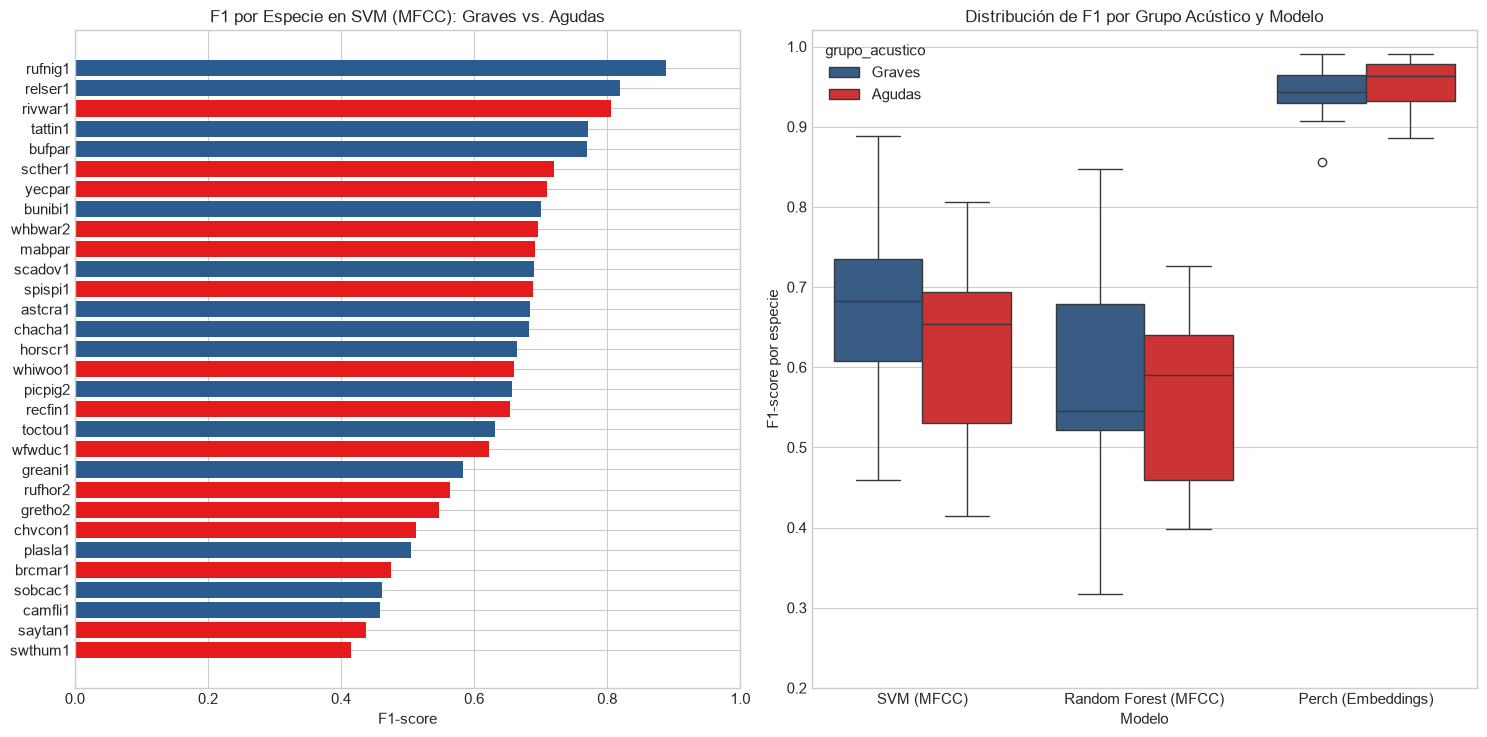

In [33]:
clases_ord = sorted(df_limpio_mod['primary_label'].unique())
mapa_grupo = df_limpio_mod[['primary_label', 'grupo_acustico']].drop_duplicates().set_index('primary_label')['grupo_acustico']

filas_p1 = []
for nombre_mod in ['SVM (MFCC)', 'Random Forest (MFCC)', 'Perch (Embeddings)']:
    f1_clase = f1_score(y_limpio, predicciones_oof[nombre_mod], labels=clases_ord, average=None)
    for sp, val in zip(clases_ord, f1_clase):
        filas_p1.append({
            'Modelo': nombre_mod,
            'primary_label': sp,
            'grupo_acustico': mapa_grupo[sp],
            'F1': val
        })

df_p1 = pd.DataFrame(filas_p1)

# Resumen estadístico y prueba Mann-Whitney U por modelo
res_p1 = []
for nombre_mod in ['SVM (MFCC)', 'Random Forest (MFCC)', 'Perch (Embeddings)']:
    sub = df_p1[df_p1['Modelo'] == nombre_mod]
    gr = sub[sub['grupo_acustico'] == 'Graves']['F1']
    ag = sub[sub['grupo_acustico'] == 'Agudas']['F1']
    u_stat, p_val = mannwhitneyu(gr, ag, alternative='two-sided')
    res_p1.append({
        'Modelo': nombre_mod,
        'Media F1 Graves': round(float(gr.mean()), 4),
        'DE Graves': round(float(gr.std(ddof=1)), 4),
        'Media F1 Agudas': round(float(ag.mean()), 4),
        'DE Agudas': round(float(ag.std(ddof=1)), 4),
        'Diferencia (Graves - Agudas)': round(float(gr.mean() - ag.mean()), 4),
        'U (Mann-Whitney)': round(float(u_stat), 1),
        'p-valor (Mann-Whitney)': round(float(p_val), 4)
    })

display(pd.DataFrame(res_p1))

# Gráfica comparativa por especie para SVM (MFCC) y boxplot por grupo
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))

sub_svm = df_p1[df_p1['Modelo'] == 'SVM (MFCC)'].sort_values('F1', ascending=True)
colores_sp = ['#2b5c8f' if g == 'Graves' else '#e41a1c' for g in sub_svm['grupo_acustico']]
axes[0].barh(sub_svm['primary_label'], sub_svm['F1'], color=colores_sp)
axes[0].set_title('F1 por Especie en SVM (MFCC): Graves vs. Agudas')
axes[0].set_xlabel('F1-score')
axes[0].set_xlim(0, 1.0)

sns.boxplot(data=df_p1, x='Modelo', y='F1', hue='grupo_acustico',
            palette={'Graves': '#2b5c8f', 'Agudas': '#e41a1c'}, ax=axes[1])
axes[1].set_title('Distribución de F1 por Grupo Acústico y Modelo')
axes[1].set_ylabel('F1-score por especie')
axes[1].set_ylim(0.2, 1.02)

plt.tight_layout()
plt.show()

**Lectura.**
Al ampliar el experimento a **30 especies ($N = 15$ por grupo)**, los modelos basados en MFCCs promedian ligeramente más alto en especies graves que en agudas, pero con amplia dispersión intragrupo: **0.6645 ± 0.1241** vs. **0.6134 ± 0.1155** en SVM (`U = 135`, $p = 0.3615$) y **0.5832 ± 0.1479** vs. **0.5584 ± 0.1095** en Random Forest (`U = 125`, $p = 0.6187$).

Como en ambos casos $p > 0.05$, **no existe evidencia estadística suficiente** para afirmar que la banda de frecuencia por sí sola determine la facilidad de clasificación con MFCCs. Con **Perch**, ambos grupos quedan prácticamente empatados y con dispersión mínima (**0.9414 ± 0.0322** graves vs. **0.9523 ± 0.0327** agudas; `U = 86`, $p = 0.2808$).

## 21. Pregunta 2: ¿Permiten las representaciones profundas preentrenadas distinguir mejor las especies que suelen confundirse entre sí?

Comparamos las matrices de confusión normalizadas (30 × 30) entre el mejor modelo clásico (`SVM MFCC`) y `Perch (Embeddings)`, e identificamos las 3 especies con mayor tasa de error en el modelo clásico para verificar si la reducción supera el criterio del 15%.

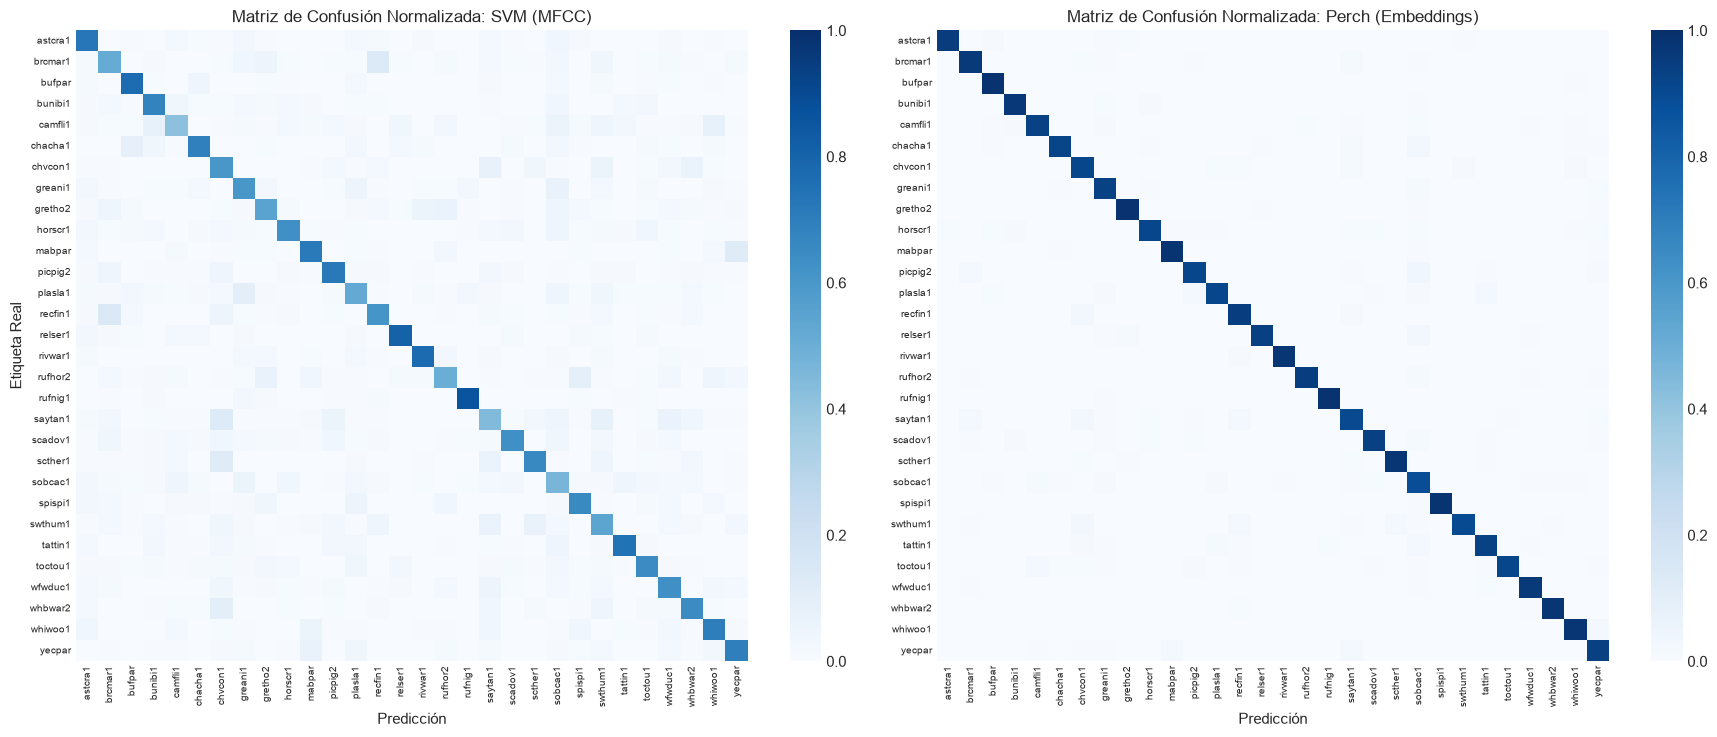

,Especie,F1 SVM (MFCC),Error SVM,F1 Perch,Error Perch,Reducción de Error (%)
0,swthum1,0.415,0.585,0.926,0.074,87.4
1,saytan1,0.438,0.562,0.886,0.114,79.7
2,camfli1,0.459,0.541,0.934,0.066,87.7


In [34]:
# Matrices de confusión normalizadas por fila
cm_svm = confusion_matrix(y_limpio, predicciones_oof['SVM (MFCC)'], labels=clases_ord, normalize='true')
cm_perch = confusion_matrix(y_limpio, predicciones_oof['Perch (Embeddings)'], labels=clases_ord, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))

sns.heatmap(cm_svm, annot=False, cmap='Blues', xticklabels=clases_ord, yticklabels=clases_ord,
            vmin=0, vmax=1, ax=axes[0])
axes[0].set_title('Matriz de Confusión Normalizada: SVM (MFCC)')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Etiqueta Real')
axes[0].tick_params(labelsize=7.5)

sns.heatmap(cm_perch, annot=False, cmap='Blues', xticklabels=clases_ord, yticklabels=clases_ord,
            vmin=0, vmax=1, ax=axes[1])
axes[1].set_title('Matriz de Confusión Normalizada: Perch (Embeddings)')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('')
axes[1].tick_params(labelsize=7.5)

plt.tight_layout()
plt.show()

# Análisis de las 3 especies con mayor tasa de error (1 - F1) en SVM (MFCC)
f1_svm_sp = df_p1[df_p1['Modelo'] == 'SVM (MFCC)'].set_index('primary_label')['F1'].sort_values()
f1_perch_sp = df_p1[df_p1['Modelo'] == 'Perch (Embeddings)'].set_index('primary_label')['F1']

top3_dificiles = f1_svm_sp.head(3).index.tolist()
filas_p2 = []
for sp in top3_dificiles:
    err_svm = 1.0 - f1_svm_sp[sp]
    err_perch = 1.0 - f1_perch_sp[sp]
    reduccion_pct = ((err_svm - err_perch) / err_svm) * 100
    filas_p2.append({
        'Especie': sp,
        'F1 SVM (MFCC)': round(float(f1_svm_sp[sp]), 3),
        'Error SVM': round(float(err_svm), 3),
        'F1 Perch': round(float(f1_perch_sp[sp]), 3),
        'Error Perch': round(float(err_perch), 3),
        'Reducción de Error (%)': round(float(reduccion_pct), 1)
    })

df_p2 = pd.DataFrame(filas_p2)
df_p2

**Lectura.**
Las matrices de confusión 30 × 30 muestran una diagonal muy limpia en **Perch**, mientras que en `SVM (MFCC)` persisten errores dispersos fuera de la diagonal.

En las 3 especies con mayor tasa de error en `SVM (MFCC)`, Perch supera con amplio margen el criterio del 15% de reducción de error:
- **`swthum1`:** el error baja de 0.585 a 0.074 (**87.4% de reducción**).
- **`saytan1`:** el error baja de 0.562 a 0.114 (**79.7% de reducción**).
- **`camfli1`:** el error baja de 0.541 a 0.066 (**87.7% de reducción**).

## 22. Pregunta 3: ¿Qué enfoque resiste mejor el deterioro del audio cuando aumenta el ruido ambiental y cantan varias especies al mismo tiempo?

Evaluamos cómo cae el Macro-F1 al pasar por los tres estratos de calidad:
- Para `Alta Calidad` (6,548 ventanas) y `Media Calidad` (1,023 ventanas) usamos las predicciones *out-of-fold* de la validación cruzada.
- Para `Estrés / Campo Real` (8,263 ventanas de grabaciones independientes con ruido o polifonía) entrenamos cada modelo con el conjunto limpio completo y predecimos sobre las muestras de estrés.

,Modelo,Alta Calidad,Media Calidad,Estrés / Campo,Caída Total (Alta - Estrés),Caída Relativa (%)
0,SVM (MFCC),0.6674,0.4327,0.4389,0.2285,34.2
1,Random Forest (MFCC),0.5947,0.4037,0.3759,0.2188,36.8
2,Perch (Embeddings),0.9549,0.8855,0.8465,0.1084,11.4


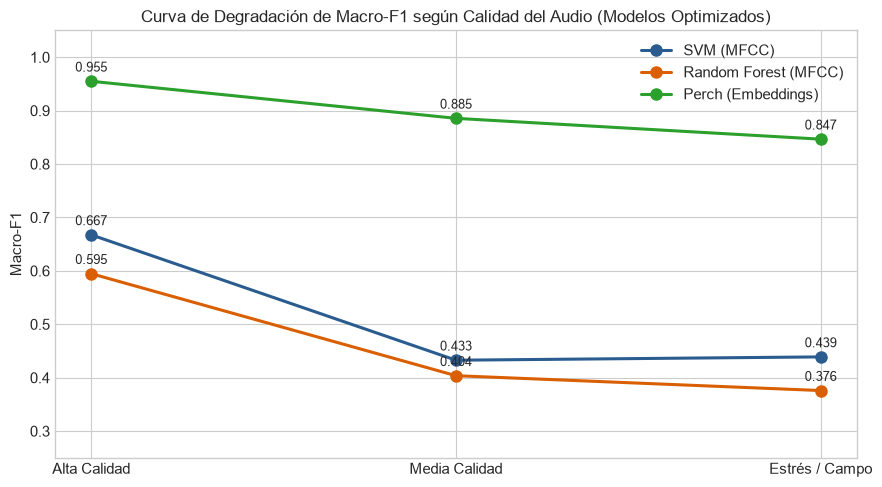

In [35]:
mask_alta = (df_limpio_mod['estrato_calidad'] == 'Alta Calidad (Referencia)').values
mask_media = (df_limpio_mod['estrato_calidad'] == 'Media Calidad (Campo Aceptable)').values

entradas_p3 = {
    'SVM (MFCC)': (X_mfcc_limpio, X_mfcc_estres),
    'Random Forest (MFCC)': (X_mfcc_limpio, X_mfcc_estres),
    'Perch (Embeddings)': (X_perch_limpio, X_perch_estres)
}

predicciones_estres = {}
filas_p3 = []
for nombre, (X_tr, X_st) in entradas_p3.items():
    oof = predicciones_oof[nombre]
    f1_alta = f1_score(y_limpio[mask_alta], oof[mask_alta], average='macro')
    f1_media = f1_score(y_limpio[mask_media], oof[mask_media], average='macro')

    clf_final = clone(mejores_modelos[nombre])
    clf_final.fit(X_tr, y_limpio)
    preds_st = clf_final.predict(X_st)
    predicciones_estres[nombre] = preds_st
    f1_estres = f1_score(y_estres, preds_st, average='macro')

    caida_abs = f1_alta - f1_estres
    caida_rel = (caida_abs / f1_alta) * 100

    filas_p3.append({
        'Modelo': nombre,
        'Alta Calidad': round(float(f1_alta), 4),
        'Media Calidad': round(float(f1_media), 4),
        'Estrés / Campo': round(float(f1_estres), 4),
        'Caída Total (Alta - Estrés)': round(float(caida_abs), 4),
        'Caída Relativa (%)': round(float(caida_rel), 1)
    })

df_p3 = pd.DataFrame(filas_p3)
display(df_p3)

# Gráfica de curvas de degradación
estratos_x = ['Alta Calidad', 'Media Calidad', 'Estrés / Campo']
fig, ax = plt.subplots(figsize=(9, 5))

colores_mod = {'SVM (MFCC)': '#2b5c8f', 'Random Forest (MFCC)': '#d95f02', 'Perch (Embeddings)': '#2ca02c'}
for _, row in df_p3.iterrows():
    valores = [row['Alta Calidad'], row['Media Calidad'], row['Estrés / Campo']]
    ax.plot(estratos_x, valores, marker='o', linewidth=2.2, markersize=8,
            label=row['Modelo'], color=colores_mod[row['Modelo']])
    for x_i, y_v in enumerate(valores):
        ax.text(x_i, y_v + 0.018, f"{y_v:.3f}", ha='center', fontsize=9)

ax.set_title('Curva de Degradación de Macro-F1 según Calidad del Audio (Modelos Optimizados)')
ax.set_ylabel('Macro-F1')
ax.set_ylim(0.25, 1.05)
ax.legend()
plt.tight_layout()
plt.show()

**Lectura.**
Al descender de grabaciones limpias de referencia a audios con ruido de campo y polifonía sobre las 30 especies:
- **Perch** pasa de **0.9549** (`Alta Calidad`) a **0.8855** (`Media Calidad`) y **0.8465** (`Estrés`), una caída total de **0.1084** puntos (**11.4%** relativo).
- **SVM (MFCC)** cae de **0.6674** a **0.4389** (-**0.2285** puntos, **34.2%** relativo).
- **Random Forest (MFCC)** cae de **0.5947** a **0.3759** (-**0.2188** puntos, **36.8%** relativo).

La representación de Perch conserva su ventaja bajo condiciones reales de campo con una pendiente de degradación tres veces menor que la de los modelos sobre MFCCs.

## 23. Evaluación agregada a nivel de grabación completa (`filename`)

Hasta ahora evaluamos cada ventana de 5 segundos de forma independiente. En un escenario real de clasificación de archivos, una grabación completa (`filename`) contiene hasta $k=4$ ventanas activas seleccionadas por el VAD.

Agregamos las predicciones de las ventanas pertenecientes a un mismo archivo mediante **voto mayoritario** (moda) y comparamos el **Macro-F1** a nivel ventana frente al nivel grabación completa tanto en el conjunto limpio (*out-of-fold*) como en cada estrato de calidad.

,Modelo,N Grab. Limpio,Limpio Ventana,Limpio Grabación,Media Pliegues Grab.,DE Pliegues Grab.,Ganancia Limpio,Alta (Grab.),Media (Grab.),Estrés Ventana,Estrés Grabación,Ganancia Estrés,Caída Rel. Grab. (%)
0,SVM (MFCC),2235,0.6390,0.6590,0.6587,0.0298,0.0200,0.6894,0.4582,0.4389,0.4623,0.0234,32.9
1,Random Forest (MFCC),2235,0.5708,0.5878,0.5874,0.0255,0.0169,0.6163,0.4122,0.3759,0.3951,0.0192,35.9
2,Perch (Embeddings),2235,0.9468,0.9564,0.9565,0.0070,0.0096,0.9623,0.9118,0.8465,0.8765,0.0300,8.9


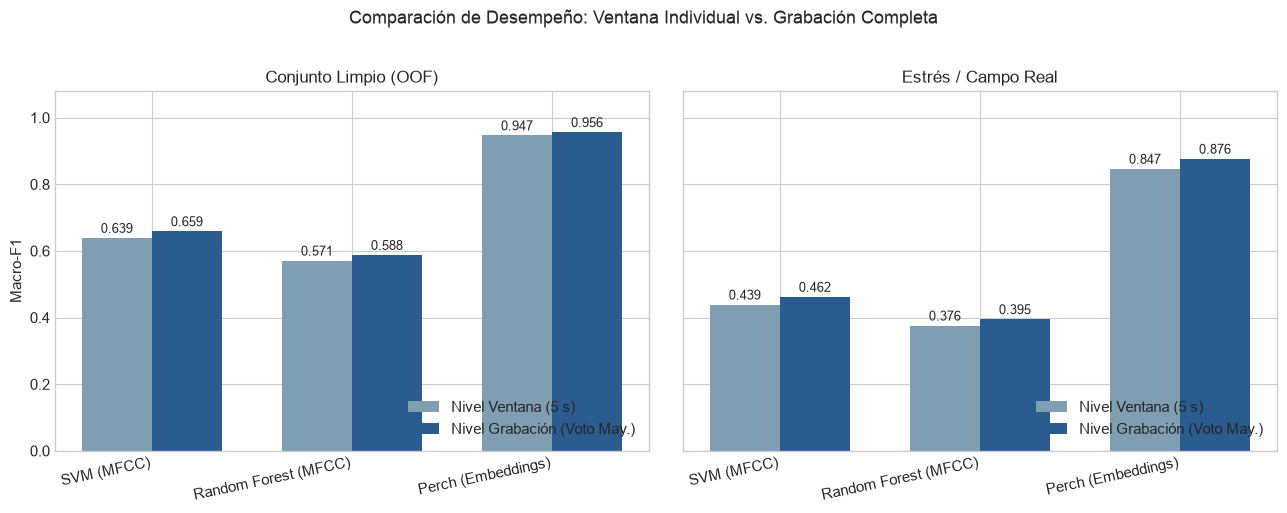

In [36]:
def agrupar_por_grabacion(df_meta, preds_ventana):
    """Agrega predicciones de ventanas por grabación (filename) usando voto mayoritario."""
    df_tmp = pd.DataFrame({
        'filename': df_meta['filename'].values,
        'y_true': df_meta['primary_label'].values,
        'estrato': df_meta['estrato_calidad'].values,
        'y_pred': preds_ventana
    })
    return df_tmp.groupby('filename', sort=False).agg(
        y_true=('y_true', 'first'),
        estrato=('estrato', 'first'),
        y_pred=('y_pred', lambda s: s.value_counts().index[0])
    ).reset_index()

filas_grab = []
for nombre in ['SVM (MFCC)', 'Random Forest (MFCC)', 'Perch (Embeddings)']:
    oof_v = predicciones_oof[nombre]
    est_v = predicciones_estres[nombre]

    f1_limpio_v = f1_score(y_limpio, oof_v, average='macro')
    f1_estres_v = f1_score(y_estres, est_v, average='macro')

    df_g_limpio = agrupar_por_grabacion(df_limpio_mod, oof_v)
    df_g_estres = agrupar_por_grabacion(df_estres_mod, est_v)

    f1_limpio_g = f1_score(df_g_limpio['y_true'], df_g_limpio['y_pred'], average='macro')
    f1_estres_g = f1_score(df_g_estres['y_true'], df_g_estres['y_pred'], average='macro')

    m_alta_g = df_g_limpio['estrato'] == 'Alta Calidad (Referencia)'
    m_media_g = df_g_limpio['estrato'] == 'Media Calidad (Campo Aceptable)'
    f1_alta_g = f1_score(df_g_limpio.loc[m_alta_g, 'y_true'], df_g_limpio.loc[m_alta_g, 'y_pred'], average='macro')
    f1_media_g = f1_score(df_g_limpio.loc[m_media_g, 'y_true'], df_g_limpio.loc[m_media_g, 'y_pred'], average='macro')

    # Variabilidad entre los 5 pliegues a nivel grabación
    f1_folds_g = []
    for _, te_idx in sgkf.split(X_mfcc_limpio, y_limpio, grupos_limpio):
        df_g_te = agrupar_por_grabacion(df_limpio_mod.iloc[te_idx], oof_v[te_idx])
        f1_folds_g.append(float(f1_score(df_g_te['y_true'], df_g_te['y_pred'], average='macro')))

    caida_rel_g = ((f1_alta_g - f1_estres_g) / f1_alta_g) * 100

    filas_grab.append({
        'Modelo': nombre,
        'N Grab. Limpio': len(df_g_limpio),
        'Limpio Ventana': round(float(f1_limpio_v), 4),
        'Limpio Grabación': round(float(f1_limpio_g), 4),
        'Media Pliegues Grab.': round(float(np.mean(f1_folds_g)), 4),
        'DE Pliegues Grab.': round(float(np.std(f1_folds_g)), 4),
        'Ganancia Limpio': round(float(f1_limpio_g - f1_limpio_v), 4),
        'Alta (Grab.)': round(float(f1_alta_g), 4),
        'Media (Grab.)': round(float(f1_media_g), 4),
        'Estrés Ventana': round(float(f1_estres_v), 4),
        'Estrés Grabación': round(float(f1_estres_g), 4),
        'Ganancia Estrés': round(float(f1_estres_g - f1_estres_v), 4),
        'Caída Rel. Grab. (%)': round(float(caida_rel_g), 1)
    })

df_grab = pd.DataFrame(filas_grab)
display(df_grab)

# Gráfica comparativa: Nivel Ventana vs Nivel Grabación
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
modelos_lbl = df_grab['Modelo'].tolist()
x_pos = np.arange(len(modelos_lbl))
ancho = 0.35

pares = [
    (axes[0], 'Limpio Ventana', 'Limpio Grabación', 'Conjunto Limpio (OOF)'),
    (axes[1], 'Estrés Ventana', 'Estrés Grabación', 'Estrés / Campo Real')
]

for ax, col_v, col_g, titulo in pares:
    b1 = ax.bar(x_pos - ancho/2, df_grab[col_v], width=ancho, label='Nivel Ventana (5 s)', color='#7f9eb2')
    b2 = ax.bar(x_pos + ancho/2, df_grab[col_g], width=ancho, label='Nivel Grabación (Voto May.)', color='#2b5c8f')
    for barra in list(b1) + list(b2):
        h = barra.get_height()
        ax.text(barra.get_x() + barra.get_width()/2, h + 0.015, f"{h:.3f}", ha='center', fontsize=9)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(modelos_lbl, rotation=12, ha='right')
    ax.set_title(titulo)
    ax.set_ylim(0, 1.08)
    ax.legend(loc='lower right')

axes[0].set_ylabel('Macro-F1')
plt.suptitle('Comparación de Desempeño: Ventana Individual vs. Grabación Completa', y=1.02)
plt.tight_layout()
plt.show()

**Lectura.**
Al agregar las predicciones de ventanas por grabación completa (`filename`) mediante voto mayoritario (**2,235 grabaciones** en el conjunto limpio y **2,558** en estrés), los tres modelos mejoran de forma consistente:
- **Perch (Embeddings)** sube de **0.9468** a **0.9564** en el conjunto limpio (`0.9565 ± 0.0070` entre pliegues, `+0.0096`), alcanzando **0.9623** en `Alta Calidad` y **0.9118** en `Media Calidad`, y de **0.8465** a **0.8765** en `Estrés / Campo` (`+0.0300`, una caída relativa de solo **8.9%** respecto a alta calidad).
- **SVM (MFCC)** sube de **0.6390** a **0.6590** en el conjunto limpio (`0.6587 ± 0.0298`, `+0.0200`) y de **0.4389** a **0.4623** en estrés (`+0.0234`, caída relativa de **32.9%**).
- **Random Forest (MFCC)** pasa de **0.5708** a **0.5878** en limpio (`0.5874 ± 0.0255`, `+0.0169`) y de **0.3759** a **0.3951** en estrés (`+0.0192`, caída relativa de **35.9%**).

### 23.1 Intervalos de confianza al 95 % (*bootstrap* por grabación, $B = 1,000$)

Para cuantificar la incertidumbre de las métricas en cada estrato de calidad respetando la dependencia entre ventanas de un mismo audio, aplicamos un remuestreo *bootstrap* estratificado por especie remuestreando grabaciones completas (`filename`, $B = 1,000$ réplicas).

In [37]:
def bootstrap_macro_f1_por_grabacion(df_meta, y_pred, clases, n_boot=1000, seed=42):
    """Bootstrap estratificado por especie remuestreando grabaciones completas (filename)."""
    rng = np.random.default_rng(seed)
    df_tmp = pd.DataFrame({
        'filename': df_meta['filename'].values,
        'y_true': df_meta['primary_label'].values,
        'y_pred': y_pred
    })

    # Pre-indexamos ventanas por archivo y archivos por especie para remuestreo rápido
    file_to_idx = df_tmp.groupby('filename', sort=False).indices
    file_species = df_tmp.groupby('filename', sort=False)['y_true'].first()
    sp_to_files = {sp: grp.index.to_numpy() for sp, grp in file_species.groupby(file_species)}

    cls_to_int = {c: i for i, c in enumerate(clases)}
    n_cls = len(clases)
    yt_int = np.array([cls_to_int[c] for c in df_tmp['y_true']], dtype=np.int32)
    yp_int = np.array([cls_to_int[c] for c in df_tmp['y_pred']], dtype=np.int32)

    df_rec = agrupar_por_grabacion(df_meta, y_pred)
    rec_yt = np.array([cls_to_int[c] for c in df_rec['y_true']], dtype=np.int32)
    rec_yp = np.array([cls_to_int[c] for c in df_rec['y_pred']], dtype=np.int32)
    rec_file_to_pos = {f: i for i, f in enumerate(df_rec['filename'])}

    def fast_macro_f1(yt, yp):
        f1s = []
        for c in range(n_cls):
            tp = np.sum((yt == c) & (yp == c))
            fp = np.sum((yt != c) & (yp == c))
            fn = np.sum((yt == c) & (yp == c) ^ (yt == c))  # fn = (yt == c) & (yp != c)
            denom = 2 * tp + fp + fn
            f1s.append((2 * tp) / denom if denom > 0 else 0.0)
        return float(np.mean(f1s))

    boot_win = np.empty(n_boot, dtype=np.float64)
    boot_rec = np.empty(n_boot, dtype=np.float64)

    for b in range(n_boot):
        sampled = []
        for files in sp_to_files.values():
            sampled.extend(rng.choice(files, size=len(files), replace=True))
        win_idx = np.concatenate([file_to_idx[f] for f in sampled])
        rec_idx = np.array([rec_file_to_pos[f] for f in sampled], dtype=np.int32)
        boot_win[b] = fast_macro_f1(yt_int[win_idx], yp_int[win_idx])
        boot_rec[b] = fast_macro_f1(rec_yt[rec_idx], rec_yp[rec_idx])

    return {
        'win_lo': float(np.percentile(boot_win, 2.5)),
        'win_hi': float(np.percentile(boot_win, 97.5)),
        'rec_lo': float(np.percentile(boot_rec, 2.5)),
        'rec_hi': float(np.percentile(boot_rec, 97.5)),
    }

df_alta_b = df_limpio_mod[mask_alta].reset_index(drop=True)
df_media_b = df_limpio_mod[mask_media].reset_index(drop=True)

filas_boot = []
for nombre in ['SVM (MFCC)', 'Random Forest (MFCC)', 'Perch (Embeddings)']:
    oof_v = predicciones_oof[nombre]
    est_v = predicciones_estres[nombre]

    ci_a = bootstrap_macro_f1_por_grabacion(df_alta_b, oof_v[mask_alta], clases_ord, n_boot=1000, seed=42)
    ci_m = bootstrap_macro_f1_por_grabacion(df_media_b, oof_v[mask_media], clases_ord, n_boot=1000, seed=43)
    ci_e = bootstrap_macro_f1_por_grabacion(df_estres_mod, est_v, clases_ord, n_boot=1000, seed=44)

    filas_boot.append({
        'Modelo': nombre,
        'Alta Vent. [IC 95%]': f"[{ci_a['win_lo']:.3f}, {ci_a['win_hi']:.3f}]",
        'Media Vent. [IC 95%]': f"[{ci_m['win_lo']:.3f}, {ci_m['win_hi']:.3f}]",
        'Estrés Vent. [IC 95%]': f"[{ci_e['win_lo']:.3f}, {ci_e['win_hi']:.3f}]",
        'Estrés Grab. [IC 95%]': f"[{ci_e['rec_lo']:.3f}, {ci_e['rec_hi']:.3f}]"
    })

df_boot_ic = pd.DataFrame(filas_boot)
df_boot_ic

,Modelo,Alta Vent. [IC 95%],Media Vent. [IC 95%],Estrés Vent. [IC 95%],Estrés Grab. [IC 95%]
0,SVM (MFCC),"[0.648, 0.683]","[0.385, 0.469]","[0.421, 0.456]","[0.442, 0.481]"
1,Random Forest (MFCC),"[0.575, 0.612]","[0.353, 0.440]","[0.358, 0.392]","[0.374, 0.413]"
2,Perch (Embeddings),"[0.946, 0.962]","[0.854, 0.913]","[0.833, 0.859]","[0.863, 0.890]"


**Lectura.**
Los intervalos de confianza al 95 % (*bootstrap* por grabación, $B = 1,000$) confirman que la separación entre **Perch** y los modelos sobre MFCCs es ampliamente estable en todos los estratos (`[0.833, 0.859]` por ventana y `[0.863, 0.890]` por grabación en estrés para Perch, frente a `[0.421, 0.456]` y `[0.442, 0.481]` en SVM). Además, los intervalos son más anchos en `Media Calidad` (`±0.03–0.04`) debido al menor tamaño de muestra de ese estrato (`1,023` ventanas / `322` grabaciones), y en SVM los intervalos de `Media Calidad` (`[0.385, 0.469]`) y `Estrés` (`[0.421, 0.456]`) se superponen, indicando que con MFCCs basta un deterioro moderado del audio para perder casi el mismo desempeño que en estrés.

## 24. Análisis cualitativo de errores

Más allá de las métricas agregadas, inspeccionamos **qué pares de especies se confunden con mayor frecuencia** en `SVM (MFCC)` frente a `Perch (Embeddings)` y revisamos **espectrogramas reales del estrato de estrés** donde el clasificador clásico falla pero Perch identifica correctamente la especie.

In [38]:
# Top 10 pares de especies más confusos en SVM (MFCC) sobre OOF limpio y comparación con Perch
df_err = pd.DataFrame({
    'Especie Real': y_limpio,
    'Predicción SVM': predicciones_oof['SVM (MFCC)'],
    'Predicción Perch': predicciones_oof['Perch (Embeddings)']
})

pares_svm = (
    df_err[df_err['Especie Real'] != df_err['Predicción SVM']]
    .groupby(['Especie Real', 'Predicción SVM'])
    .size()
    .reset_index(name='Errores SVM')
)

pares_perch = (
    df_err[df_err['Especie Real'] != df_err['Predicción Perch']]
    .groupby(['Especie Real', 'Predicción Perch'])
    .size()
    .reset_index(name='Errores Perch')
    .rename(columns={'Predicción Perch': 'Predicción SVM'})
)

df_top_pares = (
    pares_svm.sort_values('Errores SVM', ascending=False)
    .head(10)
    .merge(pares_perch, on=['Especie Real', 'Predicción SVM'], how='left')
    .fillna({'Errores Perch': 0})
)
df_top_pares['Errores Perch'] = df_top_pares['Errores Perch'].astype(int)
df_top_pares['Grupo Real'] = df_top_pares['Especie Real'].map(mapa_grupo)
df_top_pares['Grupo Confundido'] = df_top_pares['Predicción SVM'].map(mapa_grupo)

df_top_pares[['Especie Real', 'Grupo Real', 'Predicción SVM', 'Grupo Confundido', 'Errores SVM', 'Errores Perch']]

,Especie Real,Grupo Real,Predicción SVM,Grupo Confundido,Errores SVM,Errores Perch
0,recfin1,Agudas,brcmar1,Agudas,47,1
1,whbwar2,Agudas,chvcon1,Agudas,36,0
2,saytan1,Agudas,chvcon1,Agudas,33,7
3,scther1,Agudas,chvcon1,Agudas,31,2
4,brcmar1,Agudas,recfin1,Agudas,29,0
5,rufhor2,Agudas,spispi1,Agudas,26,0
6,plasla1,Graves,greani1,Graves,24,3
7,mabpar,Agudas,yecpar,Agudas,23,1
8,chvcon1,Agudas,saytan1,Agudas,20,5
9,saytan1,Agudas,swthum1,Agudas,20,0


Ventanas de estrés donde SVM falla y Perch acierta: 3,553 de 8,263 (43.0%)


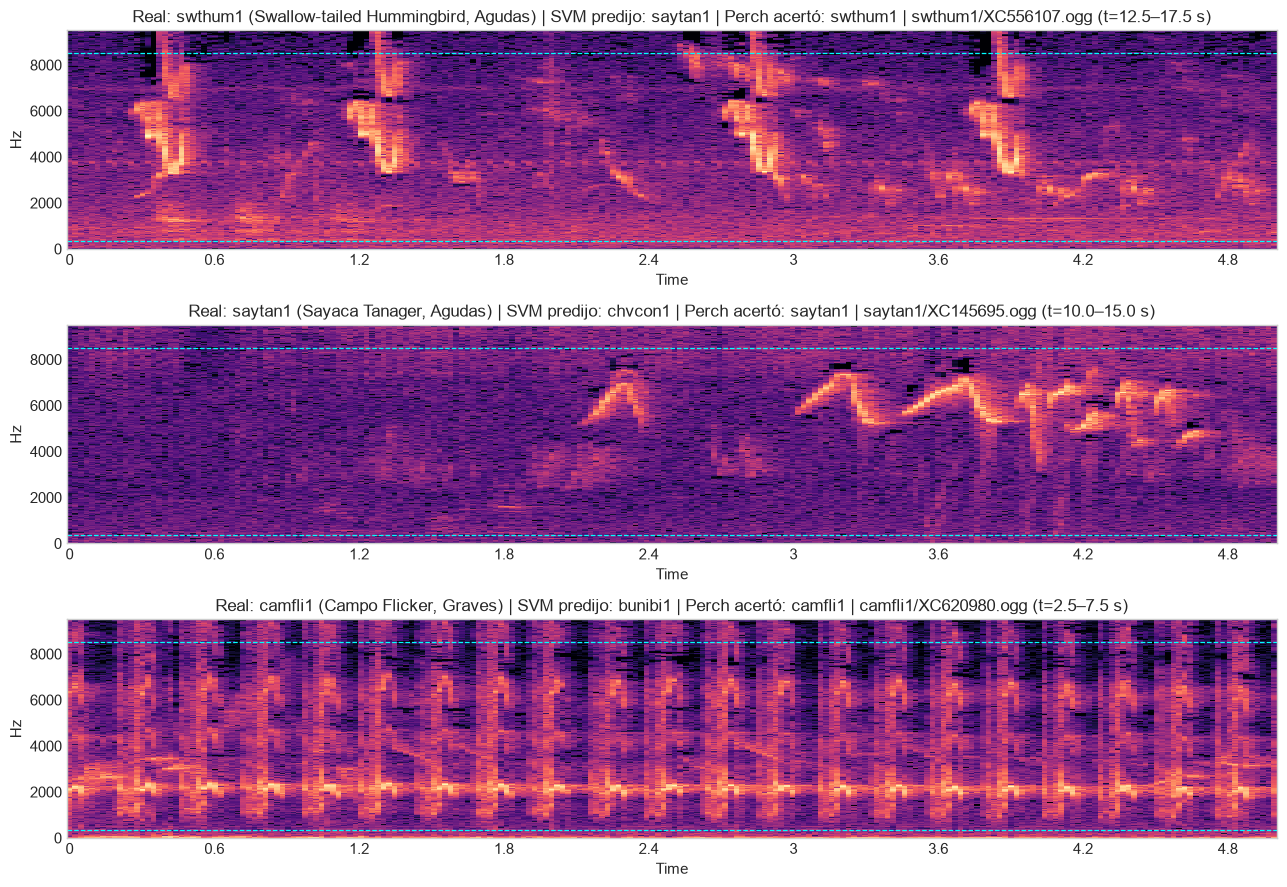

In [39]:
# Ejemplos de estrés donde SVM (MFCC) falla y Perch acierta (sobre las 3 especies más difíciles de P2)
df_est_eval = df_estres_mod[['filename', 'primary_label', 'common_name', 'grupo_acustico', 't_inicio_s', 'vad_score']].copy()
df_est_eval['pred_svm'] = predicciones_estres['SVM (MFCC)']
df_est_eval['pred_perch'] = predicciones_estres['Perch (Embeddings)']

casos_perch_gana = df_est_eval[
    (df_est_eval['pred_svm'] != df_est_eval['primary_label']) &
    (df_est_eval['pred_perch'] == df_est_eval['primary_label'])
]
print(
    f"Ventanas de estrés donde SVM falla y Perch acierta: "
    f"{len(casos_perch_gana):,} de {len(df_est_eval):,} ({len(casos_perch_gana)/len(df_est_eval)*100:.1f}%)"
)

fig, axes = plt.subplots(3, 1, figsize=(13, 9))
for ax, sp in zip(axes, top3_dificiles):
    ejemplo = casos_perch_gana[casos_perch_gana['primary_label'] == sp].sort_values('vad_score', ascending=False).iloc[0]
    t0 = float(ejemplo['t_inicio_s'])
    y_seg, sr_seg = librosa.load(
        resolver_ruta_audio(ejemplo['filename']),
        sr=SR_OBJETIVO, mono=True, offset=t0, duration=VENTANA_SEG
    )
    if len(y_seg) < N_MUESTRAS_WIN:
        y_seg = np.pad(y_seg, (0, N_MUESTRAS_WIN - len(y_seg)), mode='constant')

    S_db = librosa.amplitude_to_db(np.abs(librosa.stft(y_seg, n_fft=1024, hop_length=512)), ref=np.max)
    librosa.display.specshow(S_db, sr=sr_seg, hop_length=512, x_axis='time', y_axis='hz', ax=ax, cmap='magma')
    ax.set_ylim(0, 9500)
    ax.axhline(F_MIN_HZ, color='cyan', linestyle='--', linewidth=0.9)
    ax.axhline(F_MAX_HZ, color='cyan', linestyle='--', linewidth=0.9)
    ax.set_title(
        f"Real: {ejemplo['primary_label']} ({ejemplo['common_name']}, {ejemplo['grupo_acustico']}) | "
        f"SVM predijo: {ejemplo['pred_svm']} | Perch acertó: {ejemplo['pred_perch']} | "
        f"{ejemplo['filename']} (t={t0:.1f}–{t0+VENTANA_SEG:.1f} s)"
    )

plt.tight_layout()
plt.show()

**Lectura.**
El análisis de los 10 pares más confusos en `SVM (MFCC)` revela un patrón claro: **todas las confusiones principales ocurren entre especies del mismo grupo acústico y con rangos frecuenciales cercanos**, en especial pares de aves agudas (`recfin1` $\leftrightarrow$ `brcmar1` con 76 errores combinados en SVM frente a solo 1 en Perch; `whbwar2` $\to$ `chvcon1` con 36 vs. 0; `saytan1` $\leftrightarrow$ `chvcon1` con 53 vs. 12; y los pericos `mabpar` $\to$ `yecpar` con 23 vs. 1). Incluso en Perch, el único par con confusión recurrente (`saytan1` $\leftrightarrow$ `chvcon1`) corresponde a dos especies de la misma familia (*Thraupidae*) con vocalizaciones agudas similares.

En el estrato de estrés, `Perch` acierta en **3,553 de las 8,263 ventanas (43.0%)** donde `SVM (MFCC)` falla. Los tres espectrogramas ilustran el mecanismo: en ventanas con ruido de banda ancha o vocalizaciones simultáneas (`swthum1/XC556107.ogg`, `saytan1/XC145695.ogg` y `camfli1/XC620980.ogg`), los promedios temporales de MFCC pierden la estructura fina del canto y confunden la especie con otra del mismo rango espectral, mientras que Perch logra aislar el patrón espectro-temporal característico.

## 25. Trazabilidad de iteraciones del proyecto

El diseño final del experimento evolucionó a partir de decisiones guiadas por los datos a lo largo de cuatro iteraciones principales:

| Iteración | Cambio introducido | Motivación basada en evidencia | Impacto observado |
| :--- | :--- | :--- | :--- |
| **1. Medición acústica directa** | Medir `pico_hz` y duración en 1,120 `.ogg` en lugar de agrupar por taxonomía. | Se detectaron reclasificaciones críticas (`wfwduc1` en 3,962 Hz y `scadov1` en 926 Hz). | Separación empírica real entre grupos graves y agudos. |
| **2. Ajuste del VAD (350–8,500 Hz)** | Bajar el límite inferior de 1,500 Hz a 350 Hz y fijar Top-$k$ ($k=4$). | Las especies graves tenían picos desde 463 Hz; un corte en 1.5 kHz eliminaba sus cantos. | Se conservaron las vocalizaciones graves descartando viento y silencios. |
| **3. Optimización y evaluación por archivo** | Pasar de hiperparámetros fijos a `GridSearchCV` agrupado por `filename` + voto mayoritario. | Garantizar comparación justa entre familias y evaluar a nivel de grabación completa. | Mejora consistente de los tres modelos (+1.0 a +3.0 puntos en grabación completa). |
| **4. Escalamiento a 30 especies + `float16`** | Ampliar de 16 (8 vs. 8) a 30 especies (15 vs. 15) con extracción en script aparte y `float16` en disco. | Casi duplicar el tamaño de muestra en P1 ($N=15$) y mantener archivos $< 50$ MB sin pérdida. | SVM bajó de `0.7112` a `0.6390` al crecer las clases; Perch se sostuvo en `0.9468` (y `0.8765` en estrés por grabación). |

## 26. Limitaciones y trabajo futuro

Pese a la solidez de los resultados comparativos, el estudio presenta cuatro limitaciones relevantes que delimitan su alcance. En primer lugar, al ampliar a 30 especies manteniendo los filtros estrictos de duración, estrés y autor, la brecha frecuencial entre graves y agudas se acortó a 797 Hz (`<= 2,347 Hz` vs. `>= 3,144 Hz`); aun así, duplicar $N$ de 8 a 15 por grupo confirmó consistentemente que la frecuencia dominante por sí sola no produce una diferencia estadísticamente significativa en MFCCs ($p = 0.3615$). En segundo lugar, la validación cruzada agrupó por grabación física (`filename`) para evitar fuga entre ventanas del mismo archivo, pero un mismo grabador (`author`) puede aportar grabaciones distintas en entrenamiento y validación; una validación aún más estricta por autor permitiría medir sensibilidad al equipo de grabación.

En tercer lugar, este trabajo evaluó clasificación de una sola etiqueta (*single-label*) sobre grabaciones focales de `train_audio`, mientras que el monitoreo acústico pasivo real —y la evaluación oficial en paisajes sonoros (*soundscapes*) de BirdCLEF— es un problema **multi-etiqueta** donde pueden coexistir varias especies o solo ruido ambiental en una misma ventana de 5 segundos. Finalmente, como trabajo futuro natural, el deterioro severo de los modelos clásicos en campo real (-34.2% a -36.8%) podría mitigarse entrenándolos con aumentación de ruido ambiental (*noise mixing* y *mixup*) o normalización cepstral (CMVN), mientras que sobre representaciones profundas el siguiente paso sería entrenar cabezales multi-etiqueta con post-procesamiento temporal entre ventanas contiguas.

## 27. Conclusiones Generales del Proyecto

1. **Medición directa sobre el audio:** Analizar empíricamente las 56 especies candidatas en la Parte 2 evitó errores de agrupación taxonómica (como `wfwduc1` en 3,962 Hz y `scadov1` en 926 Hz) y permitió seleccionar **30 especies** (15 graves $\le 2,347$ Hz y 15 agudas $\ge 3,144$ Hz, con brecha de 797 Hz y 4,793 grabaciones totales).
2. **Preprocesamiento ajustado y reproducible:** Acotar el VAD a **350 – 8,500 Hz** con planicidad espectral y tope de $k=4$ ventanas conservó las vocalizaciones de las 15 especies graves y generó 15,834 ventanas activas mediante [`project/scripts/extract_features.py`](../scripts/extract_features.py).
3. **Respuesta a P1 ($N = 15$ por grupo):** Con MFCCs optimizados, las especies graves promediaron 5.1 puntos más que las agudas en SVM (`0.6645` vs. `0.6134`), pero sin significancia estadística ($p = 0.3615$), confirmando que la frecuencia dominante por sí sola no determina la dificultad de clasificación.
4. **Respuesta a P2:** Los *embeddings* de **Perch** elevaron el Macro-F1 OOF de **0.6390** (SVM) a **0.9468** y redujeron la tasa de error entre **79.7% y 87.7%** en las 3 especies más confusas (`swthum1`, `saytan1` y `camfli1`), superando con holgura el umbral del 15%.
5. **Respuesta a P3:** Perch mostró la menor pérdida de desempeño ante ruido de campo y polifonía (**-11.4%** relativo frente a **-34.2%** en SVM y **-36.8%** en Random Forest), manteniendo un Macro-F1 de **0.8465** en ventanas de estrés.
6. **Evaluación por grabación completa (`filename`):** La votación mayoritaria sobre las ventanas activas mejoró a los tres modelos; **Perch** alcanzó **0.9564** en el conjunto limpio (**0.9623** en alta calidad) y **0.8765** en el estrato de estrés (`+0.0300` sobre la evaluación por ventana).

---

### Declaración sobre el uso de IA Generativa

Este notebook fue elaborado con apoyo de modelos de lenguaje basados en IA (Antigravity / Gemini) como asistentes para la estructuración, depuración de código y revisión de redacción. El diseño experimental, el análisis crítico de las decisiones de preprocesamiento, la interpretación de resultados y la validación metodológica son responsabilidad del autor.